# Постановление задачи

**Кофейная ржавчина** - болезнь кофейного дерева, вызываемая грибом _Hemileia vastatrix_. Данная болезнь крайне опасна, она вызывает нарушение фотосинтеза, опадение листьев и при сильном поражении может вызвать гибель дерева, а потери урожая могут достигать **до 75%**. Кофейная ржавчина в XIX веке уничтожила большую часть кофейных плантаций на Цейлоне (Шри-Ланке).

Сейчас патоген распространен в местах выращивания кофейных деревьев. На его распространение особенно влияет изменения климата: рост температур и нерегулярные обильные осадки расширяют ареал патогена. Сложность борьбы с болезнью состоит **в высоком количестве штаммов** (около 50). В том числе из-за широкого распространения кофейной ржавчины, сложности борьбы и долгого срока восстановления плантаций (до 5 лет) значительно растут цены на кофе (другими причинами является логистика, климатические условия - засуха и аномальная жара).

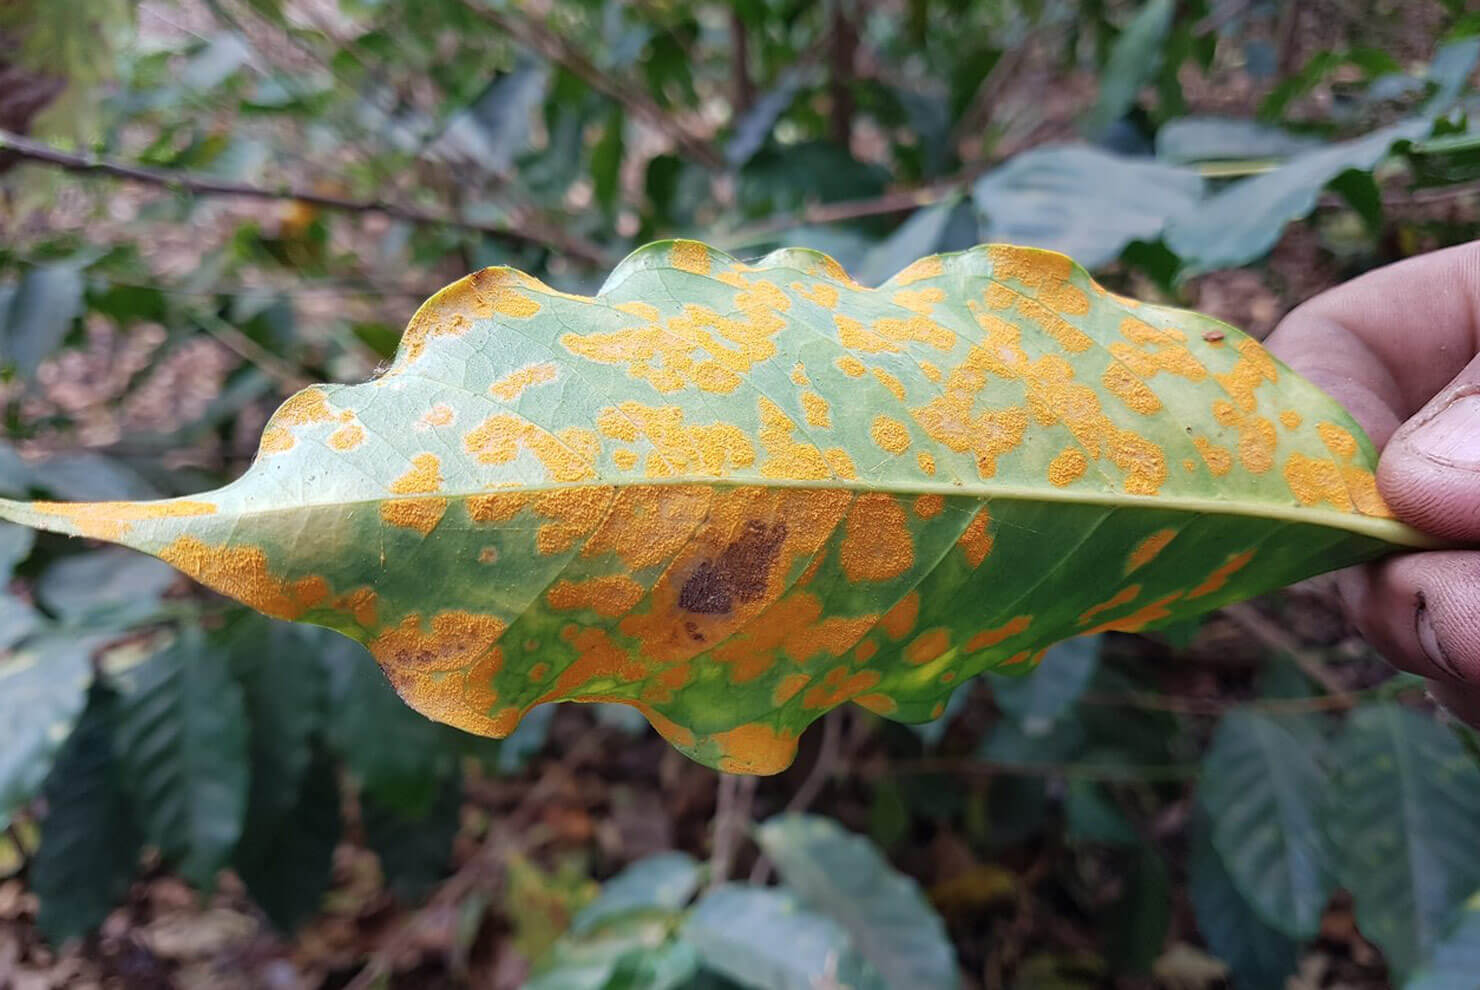
Пораженный лист кофейной ржавчиной кофейного дерева (уредостадия)

[Coffee Leaf Rust Incidence Dataset](https://zenodo.org/records/17861841#1) - набор данных, содержащий полевые наблюдения за ржавчиной кофейных листьев, собранные Институтом исследований кофе (CRI) при Кенийской организации сельскохозяйственных и животноводческих исследований (KALRO) при технической поддержке World Coffee Research (WCR). Данные были собраны в период с 2018 по 2023 год.

Основной зависимой переменной является заболеваемость ржавчиной кофейных листьев. Также в наблюдениях присутствует степень поражения ржавчиной, измеряемая как процент пораженной площади листьев.

Основным вопросом, на который будет отвечать данный анализ: При каких условиях риск развития кофейной ржавчиной повышается? Цель: выявить, какие признаки связаны с повышенным риском развития кофейной ржавчины и как именно.

# EDA

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib.patches import Patch

## Знакомство с данными

In [33]:
# загрузим данные
df = pd.read_csv('/content/Coffee_rust.csv')
df

,County,Incidence,Severity_pct,Daily_Relative_Humidity_pct,Daily_Temperature_C,Precipitation_mm_day,Leaf_Wetness_hours_day,Elevation_m,Coffee_variety,Plant_age_years,Shade_pct,Fungicide_use,Fungicide_freq_per_season,Past_outbreak_history,Lagged_incidence_prev_week,NDVI,Distance_to_nearest_infected_farm_m
0,Nyeri,0,0.0,72.48,18.33,8.04,14.59,1748,SL28,9.6,43.7,0,0,0,0,0.626,1067
1,Bungoma,0,0.0,71.38,21.27,1.18,8.07,1415,Ruiru11,2.2,17.6,0,0,0,1,0.520,233
2,Kericho,1,82.1,100.00,17.61,11.60,13.18,2032,SL28,5.5,30.4,0,0,0,0,0.546,539
3,Murang'a,1,53.4,66.37,19.08,8.49,12.43,1472,Ruiru11,5.8,5.2,0,0,0,0,0.520,211
4,Kiambu,1,53.9,74.56,18.09,1.29,16.06,1691,Ruiru11,9.5,43.8,0,0,0,0,0.645,857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9845,Nyeri,1,63.5,78.91,19.11,0.81,8.09,1608,SL34,13.7,53.6,0,0,1,0,0.564,504
9846,Kericho,1,57.4,76.42,20.21,7.18,12.00,1697,Other,18.3,11.7,0,0,0,0,0.656,2085
9847,Nyeri,1,46.2,73.99,15.00,6.55,13.20,2255,SL34,29.3,36.8,0,0,0,0,0.567,562
9848,Murang'a,0,0.0,74.95,22.80,0.94,9.60,1746,Other,21.1,18.8,1,4,0,0,0.529,2257


In [34]:
df.shape

(9850, 17)

В датасете почти 10 тысяч наблюдений и 17 признаков, ниже посмотрим на признаки

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9850 entries, 0 to 9849
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   County                               9850 non-null   object 
 1   Incidence                            9850 non-null   int64  
 2   Severity_pct                         9850 non-null   float64
 3   Daily_Relative_Humidity_pct          9850 non-null   float64
 4   Daily_Temperature_C                  9850 non-null   float64
 5   Precipitation_mm_day                 9850 non-null   float64
 6   Leaf_Wetness_hours_day               9850 non-null   float64
 7   Elevation_m                          9850 non-null   int64  
 8   Coffee_variety                       9850 non-null   object 
 9   Plant_age_years                      9850 non-null   float64
 10  Shade_pct                            9850 non-null   float64
 11  Fungicide_use                 

Колонки (признаки):
* **County** - округ Кении
* **Incidence** - заболеваемость (0 - отстутствие видимой инфекции, 1 - присутствие)
* **Severity_pct** - степень поражения, %
* **Daily_Relative_Humidity_pct** - суточная относительная влажность воздуха, %
* **Daily_Temperature_C** - суточная температура, °C
* **Precipitation_mm_day** - осадки за сутки, мм
* **Leaf_Wetness_hours_day** - часы влажности листьев в день, час
* **Elevation_m** - высота над уровнем моря, м
* **Coffee_variety** - сорт кофе
* **Plant_age_years** - возраст растений, год
* **Shade_pct** - затенение, %
* **Fungicide_use** - использование фунгицидов (1 - да, 0 - нет)
* **Fungicide_freq_per_season** - частота использования фунгицидов
* **Past_outbreak_history** - история предыдущих вспышек (1 - была вспышка, 0 - не было)
* **Lagged_incidence_prev_week** - лаговая (запаздывающая) заболеваемость за предыдущую неделю (1 - была болезнь на прошлой неделе, 0 - не было)
* **NDVI** - Normalized Difference Vegetation Index, нормализованный разностный вегетационный индекс (от -1 до 1)
* **Distance_to_nearest_infected_farm_m** - расстояние до ближайшей зараженной плантации, м


Более подробное объяснение некоторых признаков:
* **Leaf_Wetness_hours_day (LWD)** - показатель, который измеряет суммарное время (в часах), в течение которого на поверхности листьев растений присутствует свободная (жидкая) вода. Для грибов важным условием прорастания спор является наличие свободной влаги.
* **Lagged_incidence_prev_week** - показатель, отражающий уровень заболеваемости (количество новых случаев) за прошлый семидневный период. В данном датасете этот признак принимает значение 0 или 1, возможно, авторы переделали этот количественный показатель в бинарный да/нет.
* **NDVI** - показатель, который используют для оценки густоты и здоровья растительности по спутниковым снимкам или данным с дронов:
  * -1...0 - вода, снег, облака или нерастительные поверхности
  * ~0 - очень редкая растительность
  * 0.2...0.5 — начальная стадия роста культур
  * 0.6...0.95 — густая, здоровая и активно вегетирующая зеленая масса





In [36]:
df.isna().sum()

,0
County,0
Incidence,0
Severity_pct,0
Daily_Relative_Humidity_pct,0
Daily_Temperature_C,0
Precipitation_mm_day,0
Leaf_Wetness_hours_day,0
Elevation_m,0
Coffee_variety,0
Plant_age_years,0


In [37]:
df.duplicated().sum()

np.int64(0)

В датасете отсутствуют пустые значения и дубликаты, значит, можно переходить к анализу без необходимости обрабатывать пропуски и удалять дубликаты

## Анализ целевой переменной

Посмотрим на распределение заболеваемости и степени поражения

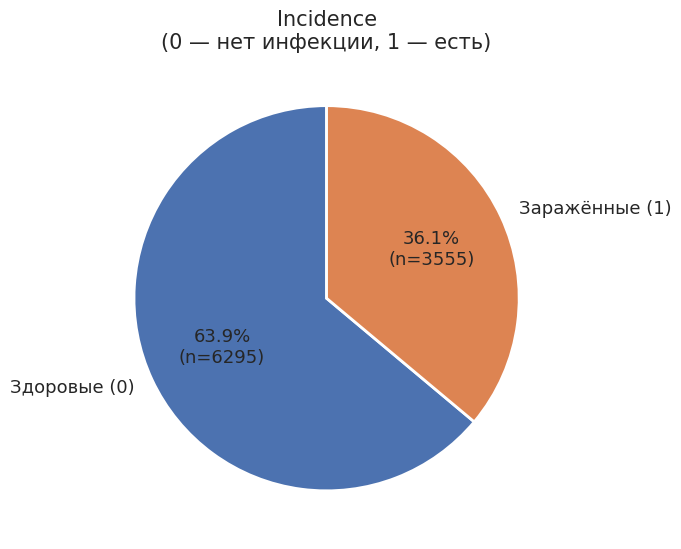

In [90]:
counts = df["Incidence"].value_counts().sort_index()
labels = ["Здоровые (0)", "Заражённые (1)"]

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    counts.values,
    labels=labels,
    autopct=lambda p: f"{p:.1f}%\n(n={int(round(p * counts.sum() / 100))})",
    startangle=90,
    wedgeprops=dict(edgecolor="white", linewidth=2),
    textprops=dict(fontsize=13),
)
ax.set_title("Incidence\n(0 — нет инфекции, 1 — есть)", fontsize=15)
plt.tight_layout()
plt.savefig("fig_incidence_pie.png", dpi=150)
plt.show()

В распрелении Incidence виден дисбаланс, большая часть наблюдений это здоровые растения (~64%). Наблюдений по заражённым образцам 3,5 тысячи

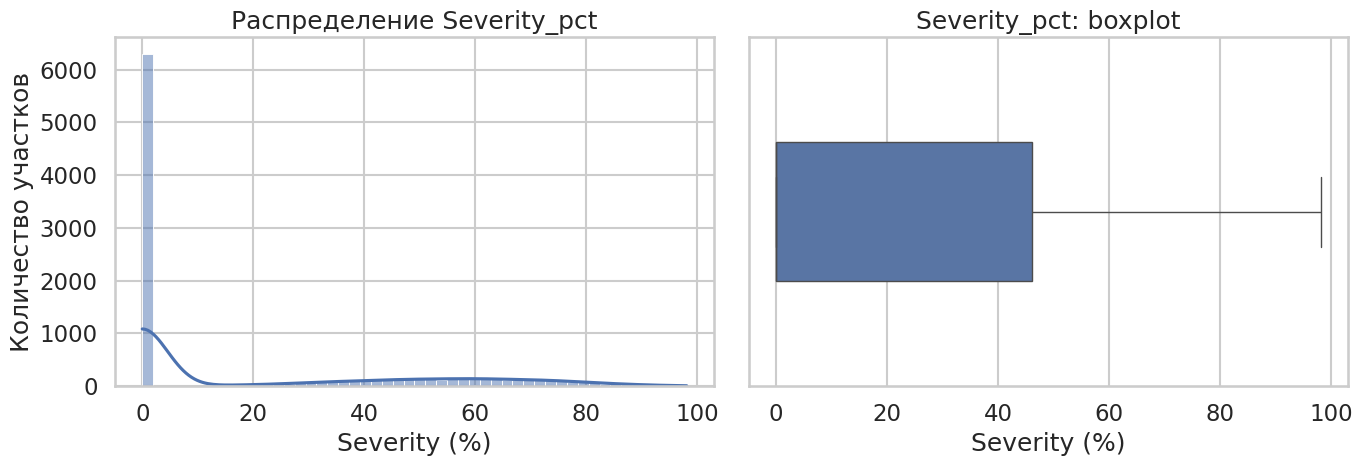

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


sns.histplot(df["Severity_pct"], bins=50, kde=True,
            ax=axes[0])
axes[0].set_xlabel("Severity (%)")
axes[0].set_ylabel("Количество участков")
axes[0].set_title("Распределение Severity_pct")


sns.boxplot(x=df["Severity_pct"], width=0.4, ax=axes[1])
axes[1].set_xlabel("Severity (%)")
axes[1].set_title("Severity_pct: boxplot")

plt.tight_layout()
plt.show()


Так как Severity_pct и Incidence признаки не независимые - когда нет болезни, степень поражения соответственно 0 %. Ниже проанализируем отдельно распределение степени поражения, где Incidence = 1

In [41]:
# разделим датасет на пораженные растение и непораженные
df_healthy = df[df["Incidence"] == 0].copy()
df_infected = df[df["Incidence"] == 1].copy()

In [42]:
# посмотрим на основные статистические показатели степени поражения зараженных участков
print(df_infected["Severity_pct"].describe().round(3))
print(f"Skewness: {df_infected['Severity_pct'].skew():.3f}")

count    3555.000
mean       55.357
std        17.716
min         4.300
25%        42.800
50%        56.100
75%        68.800
max        98.100
Name: Severity_pct, dtype: float64
Skewness: -0.136


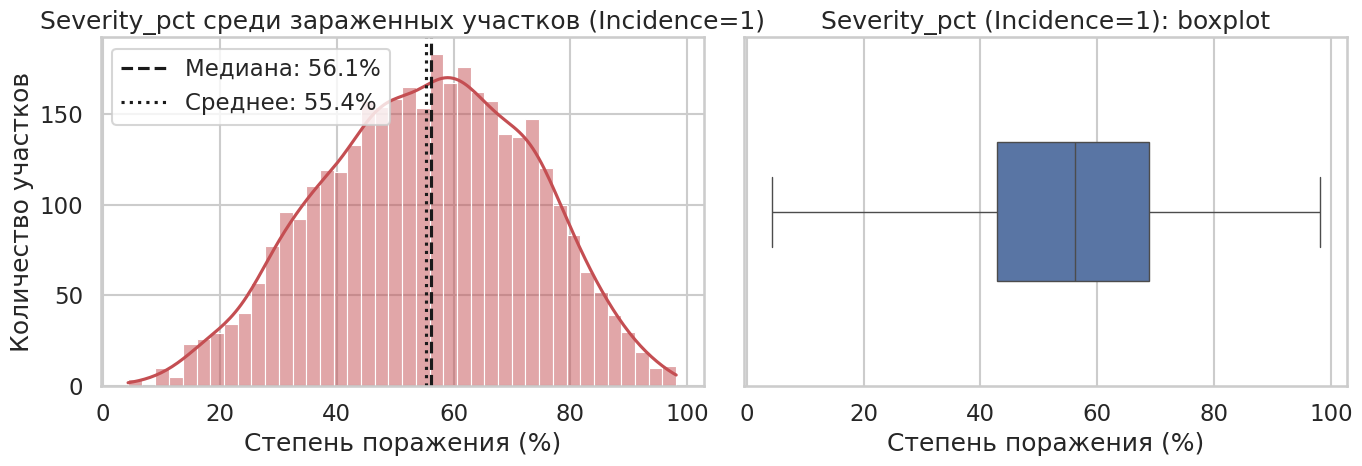

In [43]:
# построим более наглядные графики для пораженных участков
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(df_infected["Severity_pct"], bins=40, kde=True,
             color="#C44E52", ax=axes[0])
axes[0].axvline(df_infected["Severity_pct"].median(), color="k", ls="--",
                label=f"Медиана: {df_infected['Severity_pct'].median():.1f}%")
axes[0].axvline(df_infected["Severity_pct"].mean(), color="k", ls=":",
                label=f"Среднее: {df_infected['Severity_pct'].mean():.1f}%")
axes[0].set_xlabel("Степень поражения (%)")
axes[0].set_ylabel("Количество участков")
axes[0].set_title("Severity_pct среди зараженных участков (Incidence=1)")
axes[0].legend()

# Ящик с усами
sns.boxplot(x=df_infected["Severity_pct"], color="#4C72B0", width=0.4, ax=axes[1])
axes[1].set_xlabel("Степень поражения (%)")
axes[1].set_title("Severity_pct (Incidence=1): boxplot")

plt.tight_layout()
plt.savefig("fig_severity_infected_only.png", dpi=150)
plt.show()

Для пораженных участков по коэффициенту ассиметрии распределение симметрично - распределение близко к нормальному, это так же видно по почти равной медиане и среднему значению. В среднем участки поражаются на 55% ± 17%. Там **где, ржавчина поразила участок в среднем поражается более половины растений** - этот показатель очень высокий, может привести к значительным потерям урожая без своевременных защитных мер. Максимальный процент поражения - 98%, минимальный - 4%.  

## Анализ признаков

### Leaf_Wetness_hours_day

Начнем с признака **Leaf_Wetness_hours_day**. Это важный показатель, так как для прорастания спор необходимая свободная влага. Чем больше окно влажности листьев, тем больше шанс заражения растения

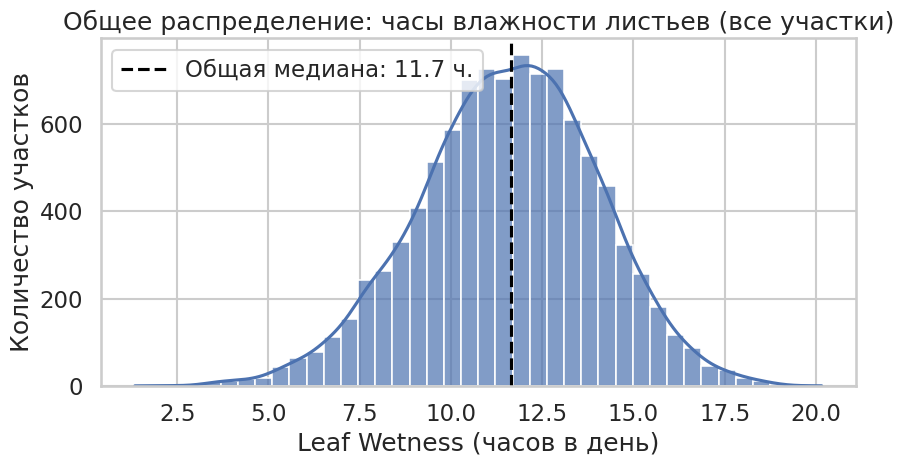

In [44]:
# Сначала посмотрим на общее распределение признака, после сравним пораженные и непораженные
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(df["Leaf_Wetness_hours_day"], bins=40, kde=True, alpha=0.7, ax=ax)

median_all = df["Leaf_Wetness_hours_day"].median()
ax.axvline(median_all, color="black", linestyle="--",
           label=f"Общая медиана: {median_all:.1f} ч.")

ax.set_title("Общее распределение: часы влажности листьев (все участки)")
ax.set_xlabel("Leaf Wetness (часов в день)")
ax.set_ylabel("Количество участков")
ax.legend()
plt.tight_layout()
plt.savefig("fig_wetness_all.png", dpi=150)
plt.show()

In [45]:
print(df["Leaf_Wetness_hours_day"].describe().round(3))
print(f"Skewness: {df["Leaf_Wetness_hours_day"].skew():.3f}")

count    9850.000
mean       11.572
std         2.463
min         1.340
25%         9.960
50%        11.660
75%        13.260
max        20.160
Name: Leaf_Wetness_hours_day, dtype: float64
Skewness: -0.175


Показатель влажности листьев варьирует от 1.3 до 20. Эти показатели соответствуют погодным характеристикам Кении - чередование сухих и дождливых сезонов с жарой. Распределение нормальное, ассиметрия отсутствует. В среднем влага присутствует на листьях около 11.5 часов. По литературным данным, для прорастания спор кофейной ржавчины необходимо 6-24ч наличия влаги. То есть в данном наборе данных **лишь около 2% участков неблагоприятны по наличию влаги** на листе для прорастания ржавчины.

Но на прорастание влияет еще **температура**, оптимальный диапазон 21-25°C, при температурном режиме ниже 12.5°C и выше 32.5°C развитие угнетается. Также кофейная ржавчина лучше прорастает **в отстутствии света** (около 4 часов). Эти признаки мы проанализируем позже.

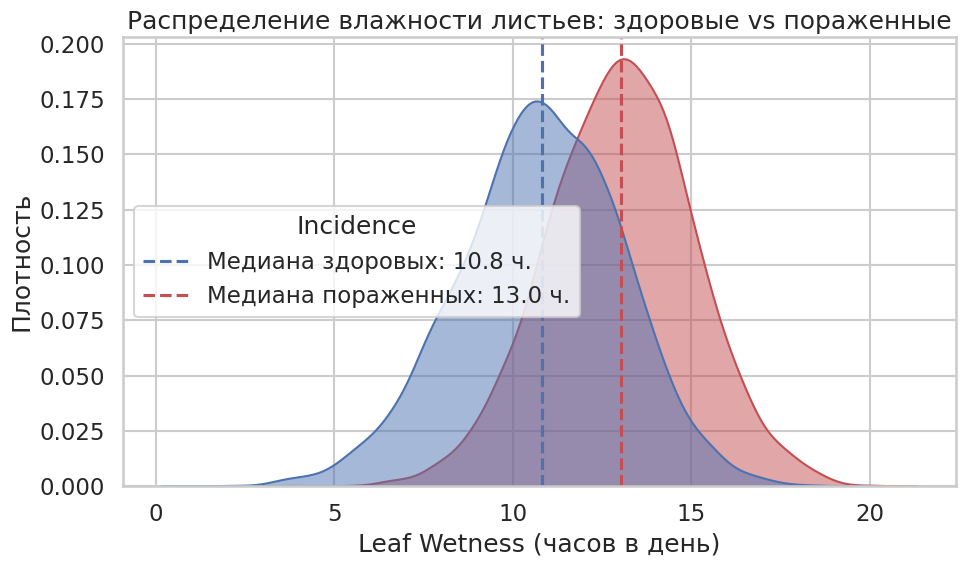

In [46]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.kdeplot(data=df, x="Leaf_Wetness_hours_day", hue="Incidence",
            fill=True, common_norm=False, palette={0: "#4C72B0", 1: "#C44E52"},
            alpha=0.5, ax=ax)

median_0 = df[df["Incidence"] == 0]["Leaf_Wetness_hours_day"].median()
median_1 = df[df["Incidence"] == 1]["Leaf_Wetness_hours_day"].median()

ax.axvline(median_0, color="#4C72B0", linestyle="--", label=f"Медиана здоровых: {median_0:.1f} ч.")
ax.axvline(median_1, color="#C44E52", linestyle="--", label=f"Медиана пораженных: {median_1:.1f} ч.")

ax.set_title("Распределение влажности листьев: здоровые vs пораженные")
ax.set_xlabel("Leaf Wetness (часов в день)")
ax.set_ylabel("Плотность")
ax.legend(title="Incidence")
plt.tight_layout()
plt.savefig("fig_wetness_by_incidence.png", dpi=150)
plt.show()


In [47]:
print(df.groupby("Incidence")["Leaf_Wetness_hours_day"]
      .agg(["mean", "median", "std", "min", "max", "count"])
      .round(2))

            mean  median   std   min    max  count
Incidence                                         
0          10.76   10.82  2.30  1.34  18.84   6295
1          13.01   13.04  2.05  3.85  20.16   3555


Распределение здоровых и пораженных различается. На практике, **для прорастания споры в среднем требуется 13ч.** Растения в среднем выдерживают почти 11ч влаги на листьях без поражения.

Можно сказать, что критической меткой влаги на поверхности листьев является 11ч. Но как говорилось ранее, на прорастание влияют и другие признаки. Влага является необходимым условием, но недостаточным: одна только свободная влага не гарантирует заражение ржавчиной. Посмотрим на кривую риска для установления более точного порога

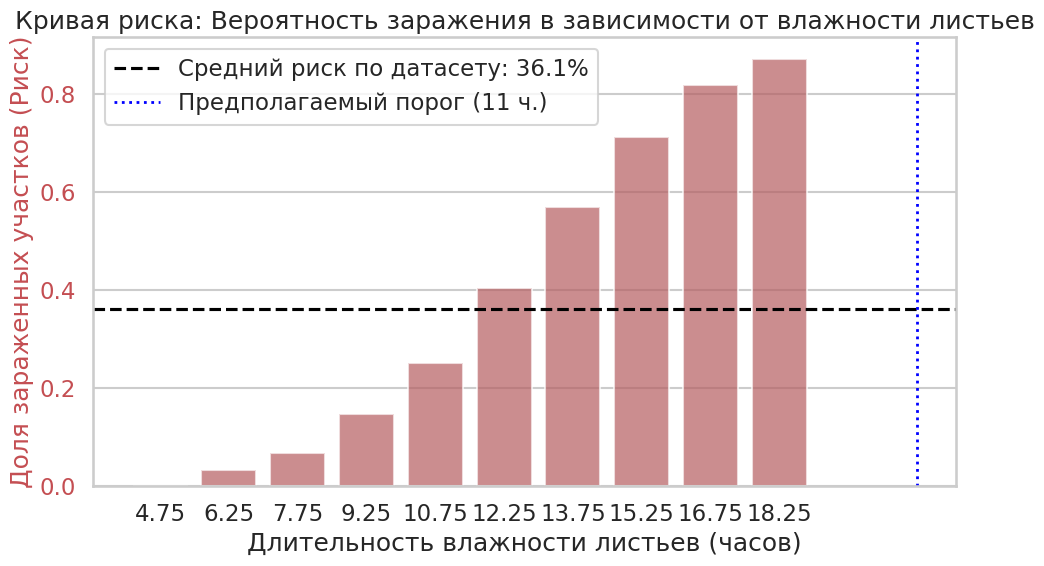

In [48]:
# Разбиваем влажность на интервалы
bins = np.arange(4, 20, 1.5)
df["wetness_bin"] = pd.cut(df["Leaf_Wetness_hours_day"], bins=bins)

# Считаем долю зараженных (риск) в каждом бине
risk_curve = df.groupby("wetness_bin", observed=True)["Incidence"].agg(["mean", "count"]).reset_index()
risk_curve = risk_curve[risk_curve["count"] >= 30]


risk_curve["mid"] = risk_curve["wetness_bin"].apply(lambda x: x.mid)

# график
fig, ax1 = plt.subplots(figsize=(10, 6))


sns.barplot(data=risk_curve, x="mid", y="mean", color="#C44E52", alpha=0.7, ax=ax1)
ax1.set_xlabel("Длительность влажности листьев (часов)")
ax1.set_ylabel("Доля зараженных участков (Риск)", color="#C44E52")
ax1.tick_params(axis='y', labelcolor="#C44E52")


ax1.axhline(df["Incidence"].mean(), color="black", linestyle="--",
            label=f"Средний риск по датасету: {df['Incidence'].mean():.1%}")

# Добавим порог в 11 часов (наша гипотеза)
ax1.axvline(11.0, color="blue", linestyle=":", lw=2, label="Предполагаемый порог (11 ч.)")

ax1.set_title("Кривая риска: Вероятность заражения в зависимости от влажности листьев")
ax1.legend(loc="upper left")

plt.tight_layout()
plt.savefig("fig_risk_curve_wetness.png", dpi=150)
plt.show()

Порог подтвердился. **11ч влаги на поверхности листьев - критический порог, где риск заражения составляет 40%** (выше 36% риска по всему датасету). Период до 10 часов является условно безопасной зоной - риск ниже 20%. А при наличии свободной влаги менее 6 часов риск составляет ниже 5%, что соответсвтует литературным данным. При увеличении количества часов от 15 до 18 риск растет до 80%, что может вызвать серьезную вспышку.

Уделим внимание округам Кении, так как они сильно отличаются по климатическим условиям. Посмотрим, как изучаемый нами признак ведет себя в разных зонах Кении

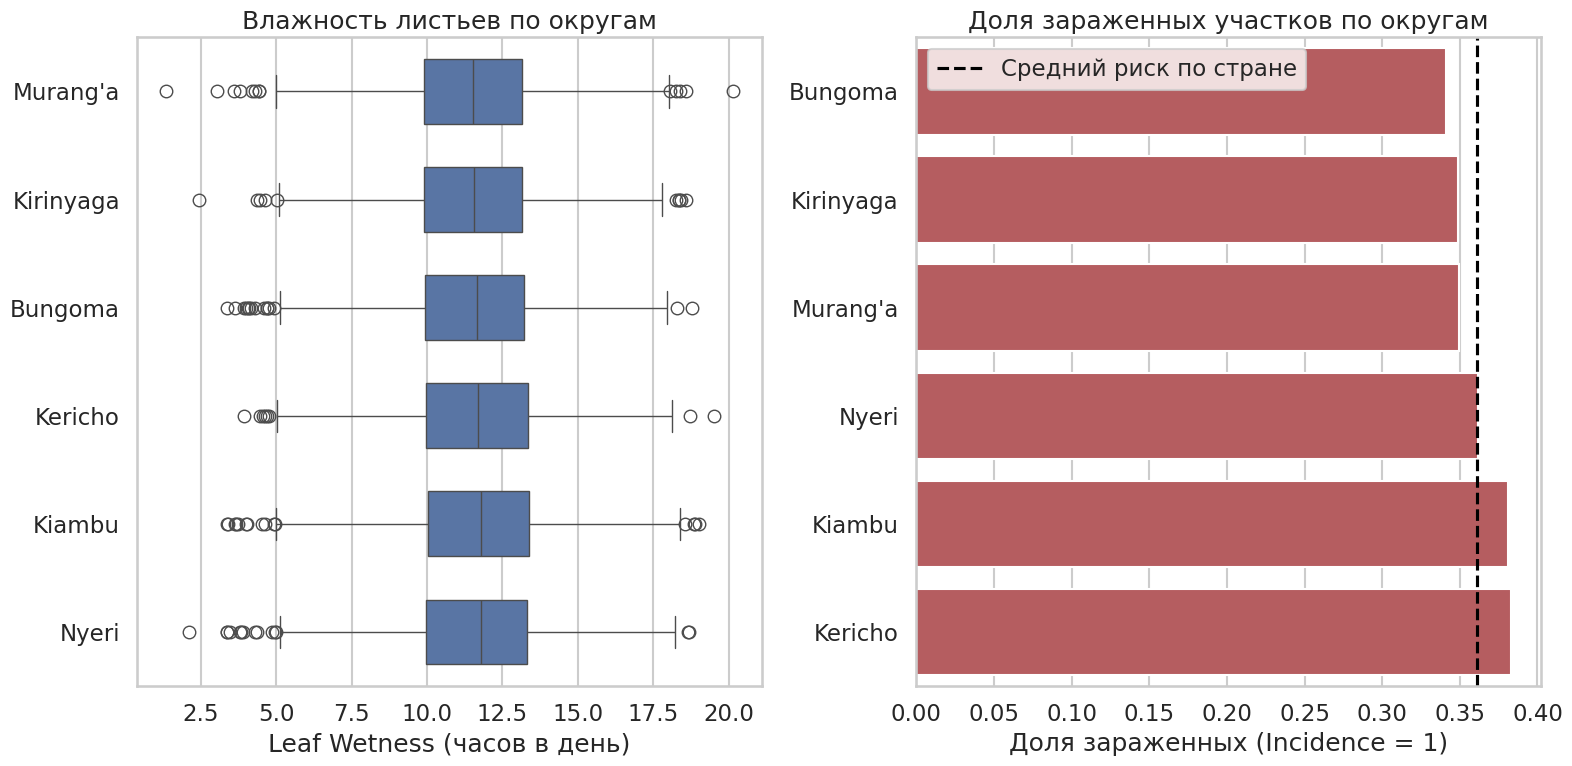

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Ящик с усами влажности листьев по округам
order_wetness = df.groupby("County")["Leaf_Wetness_hours_day"].median().sort_values().index
sns.boxplot(data=df, y="County", x="Leaf_Wetness_hours_day", order=order_wetness,
            color="#4C72B0", ax=axes[0], width=0.6)
axes[0].set_title("Влажность листьев по округам")
axes[0].set_xlabel("Leaf Wetness (часов в день)")
axes[0].set_ylabel("")

# Доля зараженных (Риск) по округам
order_risk = df.groupby("County")["Incidence"].mean().sort_values().index
sns.barplot(data=df, y="County", x="Incidence", order=order_risk,
            color="#C44E52", ax=axes[1], errorbar=None)
axes[1].axvline(df["Incidence"].mean(), color="black", linestyle="--", label="Средний риск по стране")
axes[1].set_title("Доля зараженных участков по округам")
axes[1].set_xlabel("Доля зараженных (Incidence = 1)")
axes[1].set_ylabel("")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig_county_analysis.png", dpi=150)
plt.show()

In [50]:
# Выведем сводную таблицу по округам
print(df.groupby("County").agg(
    Count=("Incidence", "count"),
    Risk_Mean=("Incidence", "mean"),
    Wetness_Median=("Leaf_Wetness_hours_day", "median"),
    Temp_Median=("Daily_Temperature_C", "median")
).sort_values("Risk_Mean", ascending=False).round(2))

           Count  Risk_Mean  Wetness_Median  Temp_Median
County                                                  
Kericho     1418       0.38           11.68        16.88
Kiambu      1808       0.38           11.78        18.98
Nyeri       1813       0.36           11.80        18.86
Murang'a    1695       0.35           11.54        19.53
Kirinyaga   1690       0.35           11.54        20.35
Bungoma     1426       0.34           11.66        20.85


Для всех округов Кении риск заражения по часам влаги на листе и температуре в среднем одинаковый. **Выводы, сделанные выше по изучаемому признаку, можно применить ко всем представленным округам Кении**

### Daily_Temperature_C

Для прорастания спор также необходима оптимальная температура. По литературным данным, оптимальный диапазон 21-25°C, при температурном режиме ниже 12.5°C и выше 32.5°C развитие угнетается. Посмотрим на распределение суточной температуры в нашем датасете и сравним с литературными источниками

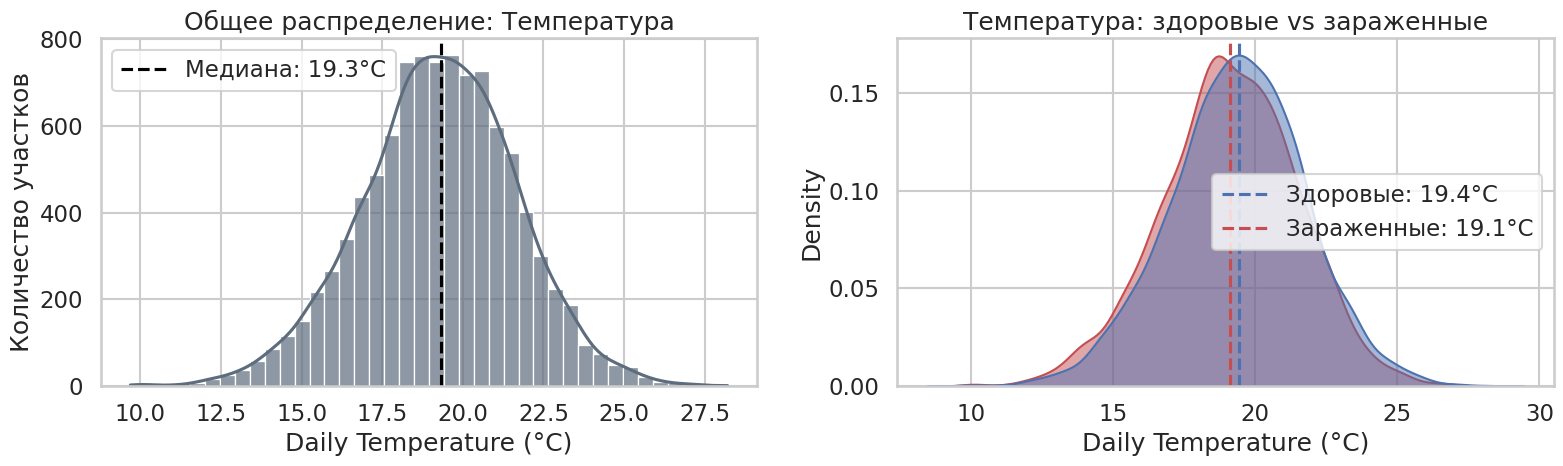

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Общее
sns.histplot(df["Daily_Temperature_C"], bins=40, kde=True,
             color="#5D6D7E", alpha=0.7, ax=axes[0])
median_t = df["Daily_Temperature_C"].median()
axes[0].axvline(median_t, color="black", linestyle="--", label=f"Медиана: {median_t:.1f}°C")
axes[0].set_title("Общее распределение: Температура")
axes[0].set_xlabel("Daily Temperature (°C)")
axes[0].set_ylabel("Количество участков")
axes[0].legend()

# По группам
sns.kdeplot(data=df, x="Daily_Temperature_C", hue="Incidence",
            fill=True, common_norm=False, palette={0: "#4C72B0", 1: "#C44E52"},
            alpha=0.5, ax=axes[1])
median_t0 = df[df["Incidence"] == 0]["Daily_Temperature_C"].median()
median_t1 = df[df["Incidence"] == 1]["Daily_Temperature_C"].median()
axes[1].axvline(median_t0, color="#4C72B0", linestyle="--", label=f"Здоровые: {median_t0:.1f}°C")
axes[1].axvline(median_t1, color="#C44E52", linestyle="--", label=f"Зараженные: {median_t1:.1f}°C")
axes[1].set_title("Температура: здоровые vs зараженные")
axes[1].set_xlabel("Daily Temperature (°C)")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig_temp_distribution.png", dpi=150)
plt.show()

In [52]:
print(df.groupby("Incidence")["Daily_Temperature_C"].agg(["mean", "median", "std", "min", "max"]).round(2))

            mean  median   std   min    max
Incidence                                  
0          19.36   19.42  2.39  9.69  28.21
1          19.08   19.11  2.41  9.91  27.02


Температура варьирует от 9 до 28 градусов. По графикам и по основным показателям статистики, распредления здоровых и пораженных участков не отличаются (как и от общего распредления) - среднее совпадает и составляет около 19 градусов. У суточной температуры не удалось выявить критический порог, **для данного датасета температура не оказывает влияния на риск заражения**

Основная масса данных находится в диапазоне 15-23 градуса, что уже соответствует благоприятным условиям для прорастания спор. Возможно, температура не показала влияния на целевую переменную, так как в данных нет информации о времени - когда и какие данные были собраны. То есть, когда температура менялась из-за дня в день, заражение или симптомы могли проявиться в один день с определенной температурой, а до этого был день с такой же температурой но заражения/симптомов не было. **При наличии временных данных можно было бы сделать анализ по временным рядам** и найти определенные закономерности.

Период от заражения до появления первых симптомов - инкубационный период кофейной ржавчины составляет от 3 до 5 недель, поэтому суточная температура может быть вообще не связана с текущим состоянием растения (заражение могло произойти 5 недель назад)

### Daily_Relative_Humidity_pct

Влажность воздуха влияет на развитие патогена. Оптимальными условиями является 80-90% влажности воздуха, по литературным данным. Но критически важным условием для прорастания споры остается наличие свободной влаги

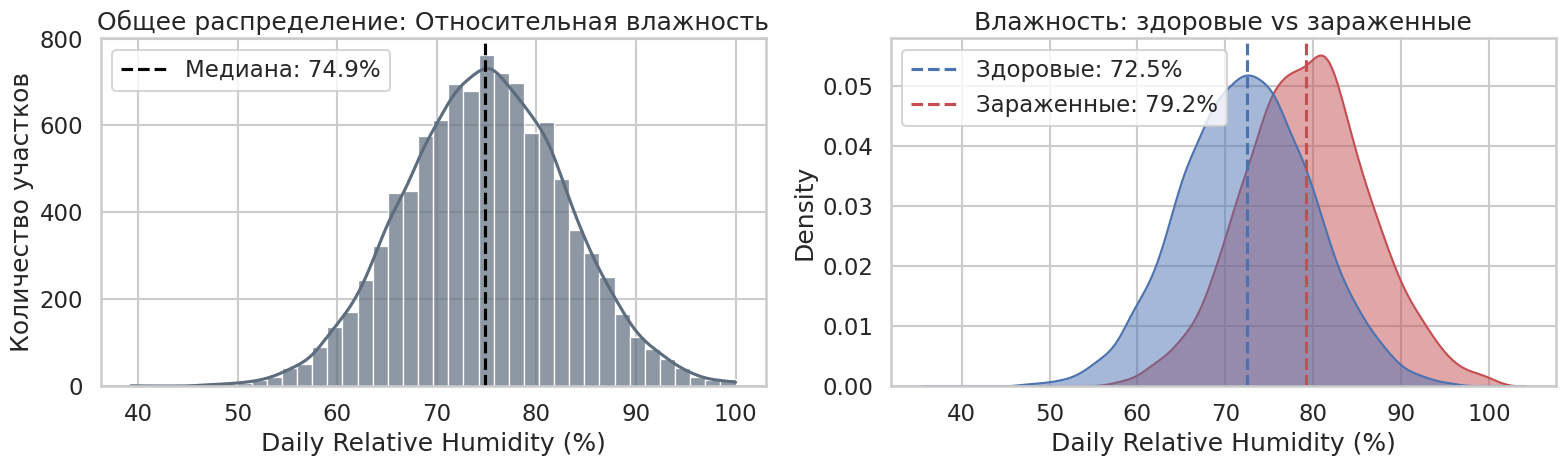

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Общее
sns.histplot(df["Daily_Relative_Humidity_pct"], bins=40, kde=True,
             color="#5D6D7E", alpha=0.7, ax=axes[0])
median_rh = df["Daily_Relative_Humidity_pct"].median()
axes[0].axvline(median_rh, color="black", linestyle="--", label=f"Медиана: {median_rh:.1f}%")
axes[0].set_title("Общее распределение: Относительная влажность")
axes[0].set_xlabel("Daily Relative Humidity (%)")
axes[0].set_ylabel("Количество участков")
axes[0].legend()

# По группам
sns.kdeplot(data=df, x="Daily_Relative_Humidity_pct", hue="Incidence",
            fill=True, common_norm=False, palette={0: "#4C72B0", 1: "#C44E52"},
            alpha=0.5, ax=axes[1])
median_rh0 = df[df["Incidence"] == 0]["Daily_Relative_Humidity_pct"].median()
median_rh1 = df[df["Incidence"] == 1]["Daily_Relative_Humidity_pct"].median()
axes[1].axvline(median_rh0, color="#4C72B0", linestyle="--", label=f"Здоровые: {median_rh0:.1f}%")
axes[1].axvline(median_rh1, color="#C44E52", linestyle="--", label=f"Зараженные: {median_rh1:.1f}%")
axes[1].set_title("Влажность: здоровые vs зараженные")
axes[1].set_xlabel("Daily Relative Humidity (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig_rh_distribution.png", dpi=150)
plt.show()

In [54]:
print(df.groupby("Incidence")["Daily_Relative_Humidity_pct"].agg(["mean", "median", "std", "min", "max"]).round(2))

            mean  median   std    min    max
Incidence                                   
0          72.42   72.45  7.50  39.28  100.0
1          79.19   79.23  7.18  52.80  100.0


Значения суточной влажности воздуха варьируют от 40% до 100% - такие колебания соответствуют переменчивому климату Кении. По графикам видно, что **средняя суточная влажность пораженных участков равна почти 80%**, когда у здоровых - 72%. Показатель 80% влажности соответствует литературным данным, но разница с распределением здоровых участков небольшая. При этом видные симптомы поражения начинаются с 52% влажности. Посмотрим на критический порог на кривой риска

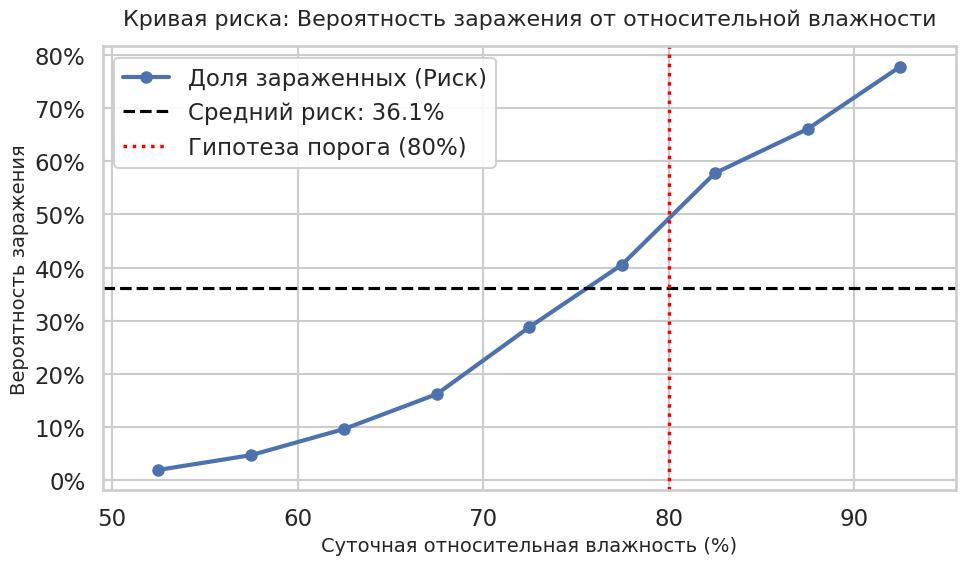

In [55]:
bins_rh = np.arange(40, 100, 5)
df["rh_bin"] = pd.cut(df["Daily_Relative_Humidity_pct"], bins=bins_rh)
risk_curve_rh = df.groupby("rh_bin", observed=True)["Incidence"].agg(["mean", "count"]).reset_index()
risk_curve_rh = risk_curve_rh[risk_curve_rh["count"] >= 20]
risk_curve_rh["mid"] = risk_curve_rh["rh_bin"].apply(lambda x: x.mid)

sns.set_theme(style="whitegrid", context="talk")

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(risk_curve_rh['mid'], risk_curve_rh['mean'],
        marker='o', markersize=8, linewidth=3, color='#4C72B0',
        label='Доля зараженных (Риск)')

ax.axhline(df["Incidence"].mean(), color="black", linestyle="--",
           label=f"Средний риск: {df['Incidence'].mean():.1%}")
ax.axvline(80, color="red", linestyle=":", linewidth=2.5,
           label="Гипотеза порога (80%)")

ax.set_title("Кривая риска: Вероятность заражения от относительной влажности", fontsize=16, pad=15)
ax.set_xlabel("Суточная относительная влажность (%)", fontsize=14)
ax.set_ylabel("Вероятность заражения", fontsize=14)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
min_val = risk_curve_rh['mid'].min()
max_val = risk_curve_rh['mid'].max()
ax.set_xlim(min_val - 3, max_val + 3)
ax.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
plt.savefig("fig_risk_curve_rh_clean.png", dpi=150)
plt.show()

На этом графике ситуация немного другая - **критический порог суточной влажности воздуха около 77%**, немного ниже 80%. При этом при влажности менее 60% риск близок к нулю, а при влажности 80-90% риск повышается до 50-70%. Крайне высокий риск заражения при влажности выше 90%.

При влажности выше 85% и часах влажности на поверхности листа более 14-15 часов крайне высок риск возникновения эпифитотия - массового распространения болезни на значительных участках. Если упустить это благоприятное окно для развития патогена кофейной ржавчины и не предпринять защитные меры вовремя, заболевание охватит не одну плантацию, а целое хозяйство или даже регион.

Важно понимать, что эти два признака взаимосвязаны. Высокая влажность воздуха не дает каплям влаги испаряться с листа, а длительное наличие свободной влаги дает спорам достаточно времени, чтобы прорасти и внедриться в устьица. Чтобы подтвердить слова посмотрим на график этих двух признаков

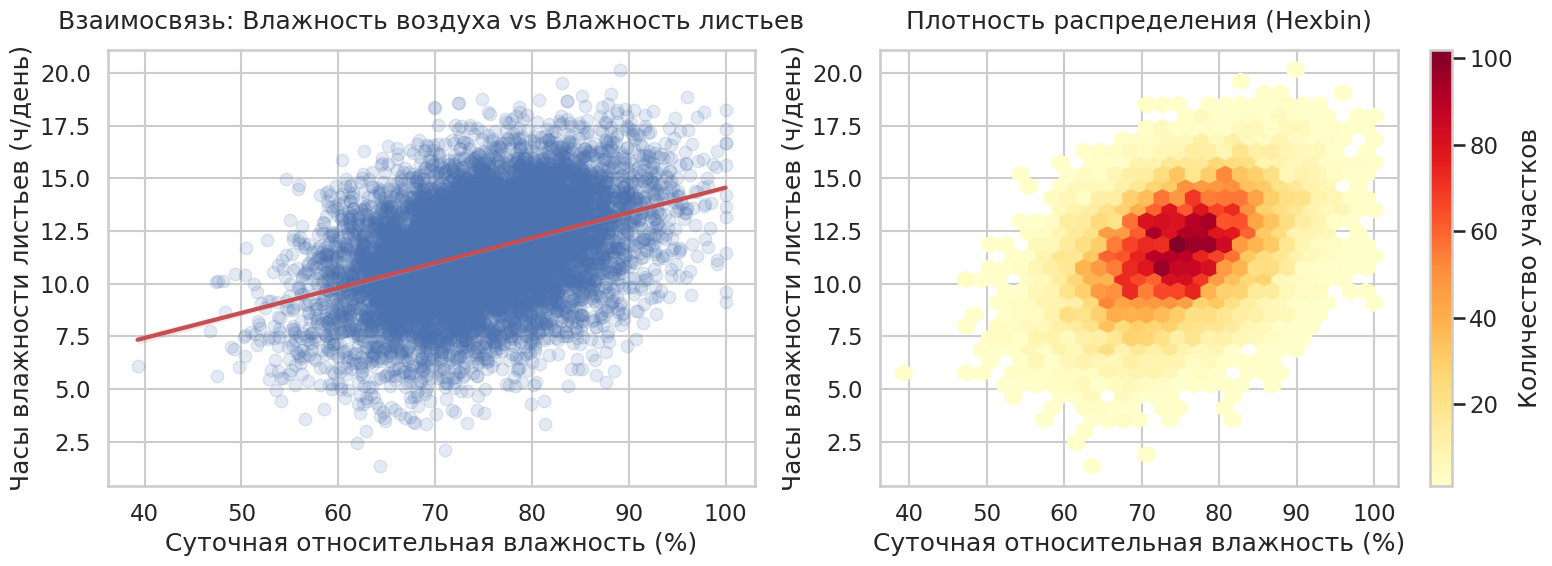

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatterplot с линией тренда
sns.regplot(data=df, x="Daily_Relative_Humidity_pct", y="Leaf_Wetness_hours_day",
            ax=axes[0], scatter_kws={'alpha': 0.15, 'color': '#4C72B0'},
            line_kws={'color': '#C44E52', 'linewidth': 3})
axes[0].set_title("Взаимосвязь: Влажность воздуха vs Влажность листьев", pad=15)
axes[0].set_xlabel("Суточная относительная влажность (%)")
axes[0].set_ylabel("Часы влажности листьев (ч/день)")

# Hexbin plot показывает плотность скопления точек
hb = axes[1].hexbin(df["Daily_Relative_Humidity_pct"], df["Leaf_Wetness_hours_day"],
                    gridsize=30, cmap="YlOrRd", mincnt=1)
axes[1].set_title("Плотность распределения (Hexbin)", pad=15)
axes[1].set_xlabel("Суточная относительная влажность (%)")
axes[1].set_ylabel("Часы влажности листьев (ч/день)")
fig.colorbar(hb, ax=axes[1], label="Количество участков")

plt.tight_layout()
plt.savefig("fig_rh_vs_wetness.png", dpi=150)
plt.show()

In [57]:
pearson_r, _ = pearsonr(df["Daily_Relative_Humidity_pct"], df["Leaf_Wetness_hours_day"])
spearman_r, _ = spearmanr(df["Daily_Relative_Humidity_pct"], df["Leaf_Wetness_hours_day"])
print(f"Корреляция Пирсона: {pearson_r:.3f}")
print(f"Корреляция Спирмена: {spearman_r:.3f}")

Корреляция Пирсона: 0.389
Корреляция Спирмена: 0.376


По коэффиценту корреляции Пирсона и коэффициенту корелляции Спирмена связь между относительной влажностью и часами влажности листьев прямая линейная, но умеренная - коэффициент меньше 0.5. По графику так же видна линейная положительная связь, при этом большинство участков чаще фиксировали влажность 70-80% и часы влажности листьев составляли 11-14 часов.

Значения этих коэффициентов подтверждают слова о том, что при повышении относительной влажности воздуха влага на листьях сохраняется дольше. Но это связь невыраженная, возможно влияют и другие признаки, например скорость ветра, температура воздуха и затенение.

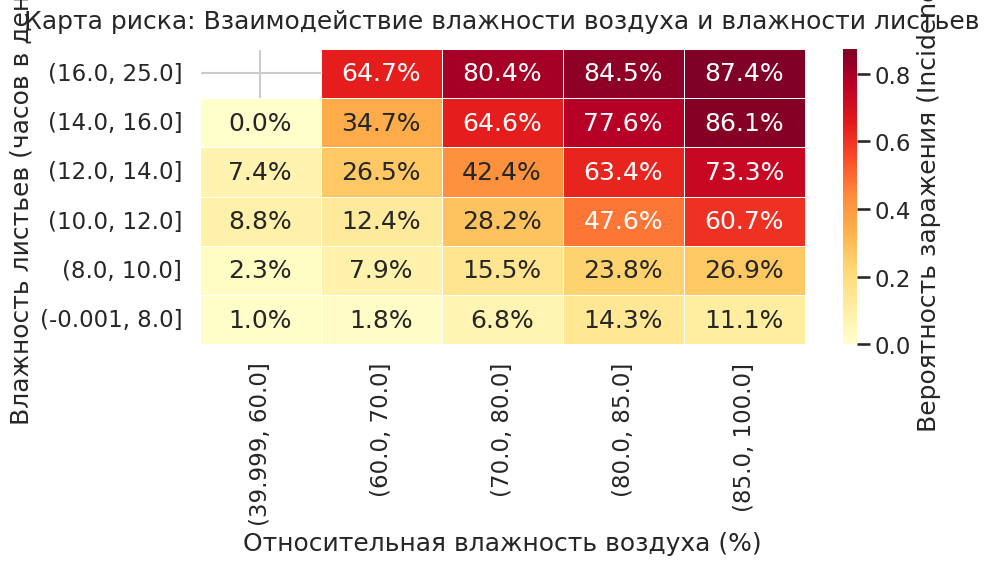

In [58]:
df['RH_bin'] = pd.cut(df['Daily_Relative_Humidity_pct'], bins=[40, 60, 70, 80, 85, 100], include_lowest=True)
df['Wetness_bin'] = pd.cut(df['Leaf_Wetness_hours_day'], bins=[0, 8, 10, 12, 14, 16, 25], include_lowest=True)

pivot_risk = df.pivot_table(index='Wetness_bin', columns='RH_bin', values='Incidence', aggfunc='mean', observed=True)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot_risk, annot=True, fmt=".1%", cmap="YlOrRd",
            linewidths=.5, cbar_kws={'label': 'Вероятность заражения (Incidence)'}, ax=ax)

ax.set_title("Карта риска: Взаимодействие влажности воздуха и влажности листьев", pad=15)
ax.set_xlabel("Относительная влажность воздуха (%)")
ax.set_ylabel("Влажность листьев (часов в день)")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("fig_heatmap_rh_wetness.png", dpi=150)
plt.show()

По карте риска взаимодействия этих признаков можно увидеть подтверждение предыдущим выводам: при влажности листьев от 14 часов и относительной влажности воздуха более 85% риск возникновения болезни близок к 90%. Эти показатели крайне сильно влияют на целевую переменную - заболеваемость кофейной ржавчиной.

Однако стоит обратить внимание на сочетание высокой влажности (85-100%) и непродолжительной влаги на листьях (до 8 часов) - риск поражения всего 11%. Это говорит о том, что **главным лимитирующим фактором является именно часы влажности листьев**. Влажность воздуха лишь способствует сохранению влаги, но при других факторах (солнце, высокая температура, отсутствие осадков) продолжительность сохранения влаги может упасть.

### Shade_pct

По литературным данным, **благоприятными условиями** для прорастания спор кофейной ржавчины является **отстутствие света или крайне низкая освещенность (от 4 до 9 часов)**. Наш показатель показывает процент затенения. Можно предположить, что риск заражения будет высок для выского процента тени на участке.

При этом тень способствует сохранению влаги на листе и также защищает растение от перегрева. Само кофейное дерево предпочитает расти в полутени, в дикой природе это кустарник нижнего яруса тропического леса

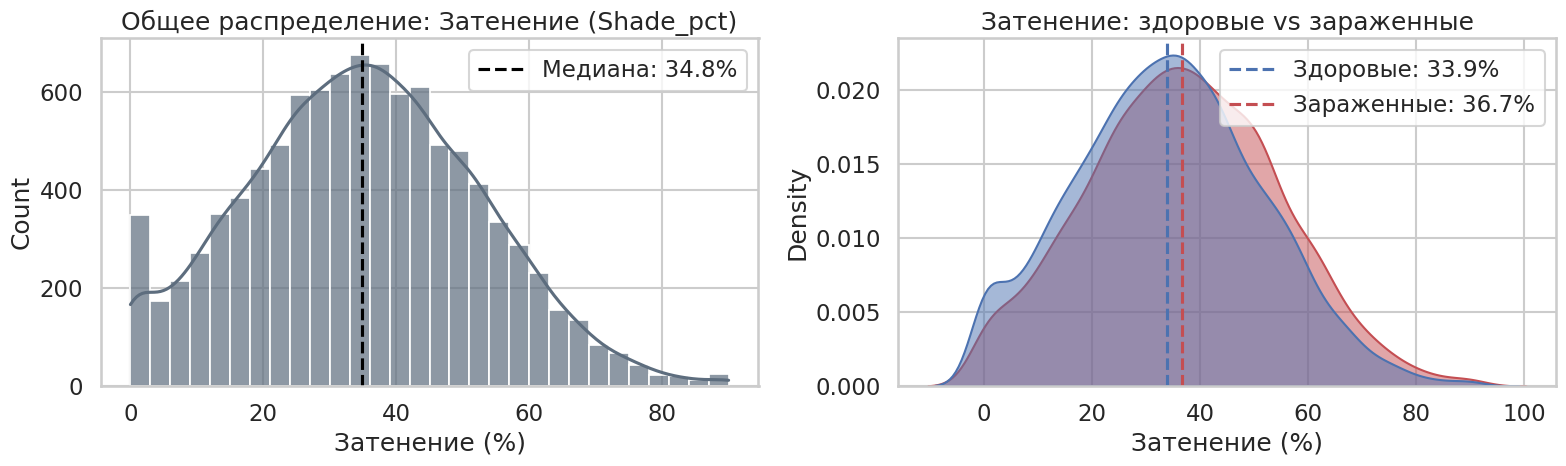

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Общее
sns.histplot(df["Shade_pct"], bins=30, kde=True, color="#5D6D7E", alpha=0.7, ax=axes[0])
median_shade = df["Shade_pct"].median()
axes[0].axvline(median_shade, color="black", linestyle="--", label=f"Медиана: {median_shade:.1f}%")
axes[0].set_title("Общее распределение: Затенение (Shade_pct)")
axes[0].set_xlabel("Затенение (%)")
axes[0].legend()

# По группам
sns.kdeplot(data=df, x="Shade_pct", hue="Incidence", fill=True, common_norm=False,
            palette={0: "#4C72B0", 1: "#C44E52"}, alpha=0.5, ax=axes[1])
median_s0 = df[df["Incidence"] == 0]["Shade_pct"].median()
median_s1 = df[df["Incidence"] == 1]["Shade_pct"].median()
axes[1].axvline(median_s0, color="#4C72B0", linestyle="--", label=f"Здоровые: {median_s0:.1f}%")
axes[1].axvline(median_s1, color="#C44E52", linestyle="--", label=f"Зараженные: {median_s1:.1f}%")
axes[1].set_title("Затенение: здоровые vs зараженные")
axes[1].set_xlabel("Затенение (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig_shade_distribution.png", dpi=150)
plt.show()

In [60]:
print(df["Shade_pct"].describe().round(3))
print(f"Skewness: {df["Shade_pct"].skew():.3f}")

count    9850.000
mean       34.997
std        17.562
min         0.000
25%        22.700
50%        34.800
75%        47.000
max        90.000
Name: Shade_pct, dtype: float64
Skewness: 0.144


In [61]:
print(df.groupby("Incidence")["Shade_pct"].agg(["mean", "median", "std", "min", "max"]).round(2))

            mean  median    std  min   max
Incidence                                 
0          33.95    33.9  17.42  0.0  90.0
1          36.85    36.7  17.67  0.0  90.0


Распределение близко к нормальному, как и общее, так и по группам. Среднее у здоровых участков составляет 34% затенения, зараженных - почти 37%. Разницы почти нет, учитывая что и у общего распределения среднее составляет 35% затенения. Половина записей по участкам имеет этот показатель.

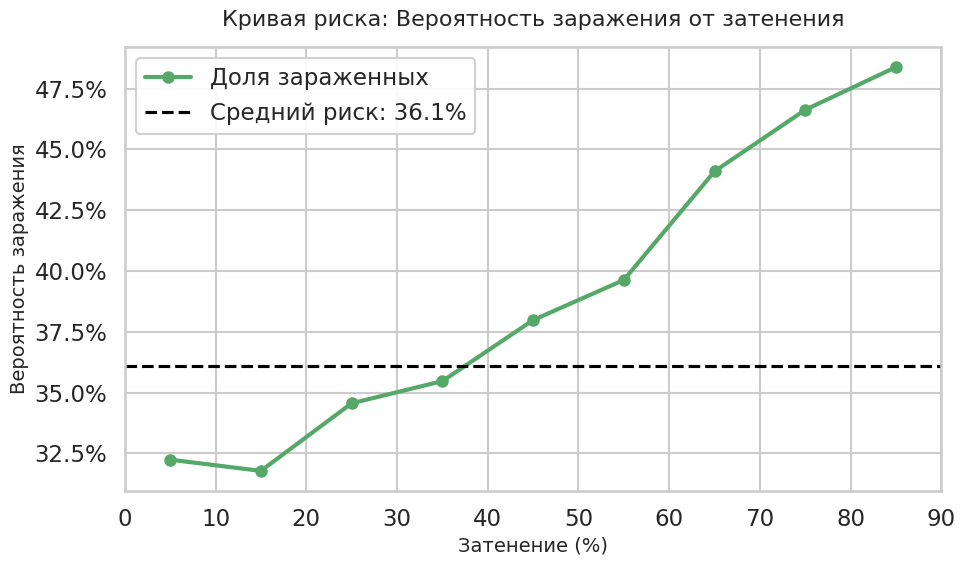

In [62]:
min_s = df["Shade_pct"].min()
max_s = df["Shade_pct"].max()
# Делаем бины по 10% (или 20%, в зависимости от разброса данных)
bins_s = np.arange(np.floor(min_s/10)*10, np.ceil(max_s/10)*10 + 10, 10)

df["shade_bin"] = pd.cut(df["Shade_pct"], bins=bins_s)
risk_curve_s = df.groupby("shade_bin", observed=True)["Incidence"].agg(["mean", "count"]).reset_index()
risk_curve_s = risk_curve_s[risk_curve_s["count"] >= 30]
risk_curve_s["mid"] = risk_curve_s["shade_bin"].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(risk_curve_s['mid'], risk_curve_s['mean'], marker='o', markersize=8, linewidth=3, color='#55A868', label='Доля зараженных')
ax.axhline(df["Incidence"].mean(), color="black", linestyle="--", label=f"Средний риск: {df['Incidence'].mean():.1%}")

ax.set_title("Кривая риска: Вероятность заражения от затенения", fontsize=16, pad=15)
ax.set_xlabel("Затенение (%)", fontsize=14)
ax.set_ylabel("Вероятность заражения", fontsize=14)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

ax.set_xticks(np.arange(bins_s[0], bins_s[-1]+1, 10))
ax.legend(loc='best', framealpha=0.9)
plt.tight_layout()
plt.savefig("fig_risk_curve_shade.png", dpi=150)
plt.show()

На кривой риск по мере увеличения процента затенения растет на 10% - рост есть, но слабый. Максимальный риск при затенении выше 80% составляет меньше 50%. **Процент затенения не оказывает большого влияния на пораженность**

###Precipitation_mm_day

Дождь способствует распространению спор и создает свободную влагу на листе для прорастания спор, может смывать фунгициды (особенно контактные, которые сохраняются лишь на поверхности листа, не проникая внутрь - в борьбе с кофейной ржавчиной используют медьсодержащие препараты, которые являются контактными). Системные фунгициды не подвержены вымыванию, если уже успели проникнуть в растение - им нужно 1-3 часа. Для проведения фунгицидных обработок важно учитывать погодные условия. В Кении два сезона дождей - с марта по июнь (сильные затяжные дожди) и с октября по декабрь (короткие, по длительности часто меньше часа).

Само кофейное дерево крайне требовательно к влаге.

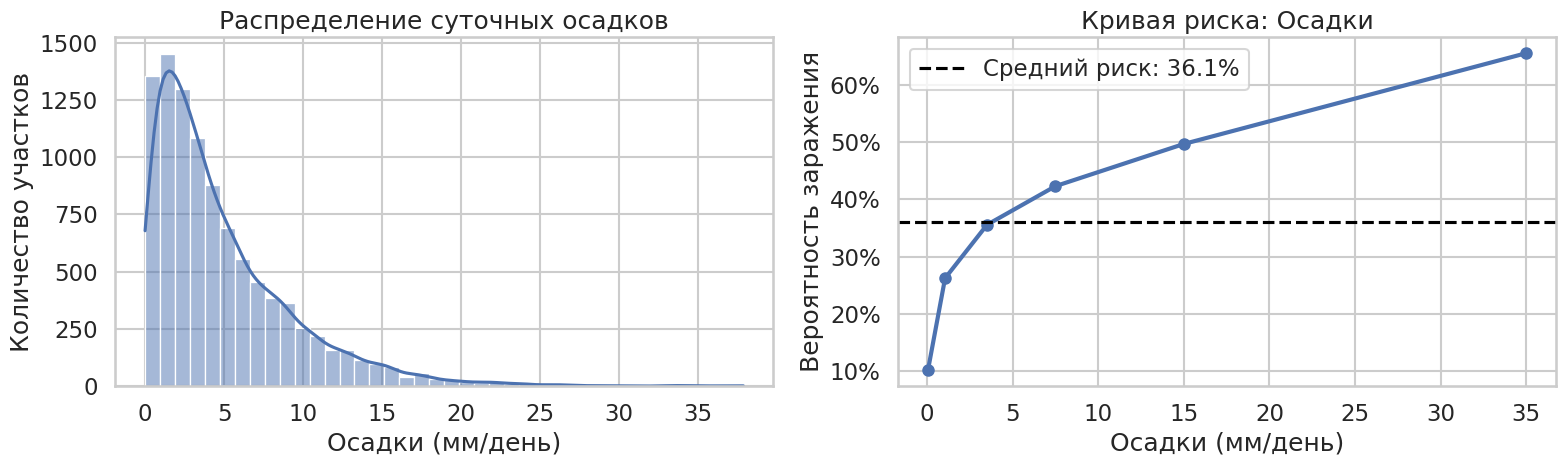

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Распределение
sns.histplot(df["Precipitation_mm_day"], bins=40, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set_title("Распределение суточных осадков")
axes[0].set_xlabel("Осадки (мм/день)")
axes[0].set_ylabel("Количество участков")

# 2. Кривая риска (бины: 0-1, 1-5, 5-10, 10-20, 20+)
bins_p = [0, 0.1, 2, 5, 10, 20, 50]
df["precip_bin"] = pd.cut(df["Precipitation_mm_day"], bins=bins_p, include_lowest=True)
risk_curve_p = df.groupby("precip_bin", observed=True)["Incidence"].agg(["mean", "count"]).reset_index()
risk_curve_p = risk_curve_p[risk_curve_p["count"] >= 30]
risk_curve_p["mid"] = risk_curve_p["precip_bin"].apply(lambda x: x.mid)

ax2 = axes[1]
ax2.plot(risk_curve_p['mid'], risk_curve_p['mean'], marker='o', markersize=8, linewidth=3, color='#4C72B0')
ax2.axhline(df["Incidence"].mean(), color="black", linestyle="--", label=f"Средний риск: {df['Incidence'].mean():.1%}")
ax2.set_title("Кривая риска: Осадки")
ax2.set_xlabel("Осадки (мм/день)")
ax2.set_ylabel("Вероятность заражения")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax2.legend()

plt.tight_layout()
plt.savefig("fig_precipitation.png", dpi=150)
plt.show()

In [64]:
df['Precipitation_mm_day'].describe()

,Precipitation_mm_day
count,9850.000000
mean,4.850645
std,4.398153
min,0.000000
25%,1.660000
50%,3.530000
75%,6.780000
max,37.900000


Распределение несимметрично - у основной части записей осадков было незначительное количество - у 75% данных - менее 7 мм в сутки, что соответствует сезону дождей. Большой пик на днях без дождя - возможно, вне сезона дождей.


In [65]:
print(df.groupby("Incidence")["Precipitation_mm_day"].agg(["mean", "median", "std", "min", "max"]).round(2))

           mean  median   std   min    max
Incidence                                 
0          4.25    3.08  3.93  0.00  37.44
1          5.92    4.47  4.95  0.02  37.90


Среднее по осадкам между здоровыми и пораженными отличается несильно - на 1.5 мм в сутки. Однако, на кривой риска **пороговым значением является около 7 мм в день**. Это значение соответствует сезону дождей. Так, риск растет при начале сезона дождей.

Также при отметке в 35 мм в сутки риск растет до почти 70%. При затяжных ливнях растения крайне подвержены кофейной ржавчине. Высокие осадки повышают количество часов свободной воды на листе, а это является критическим фактором для прорастания спор

In [66]:
summary_precip = df.groupby("County")["Precipitation_mm_day"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Max="max"
).sort_values("Mean", ascending=False)

print("Осадки по регионам (мм/день)")
print(summary_precip.round(2))

Осадки по регионам (мм/день)
           Count  Mean  Median    Max
County                               
Kiambu      1808  5.08    3.70  37.44
Bungoma     1426  4.95    3.55  33.71
Kirinyaga   1690  4.83    3.50  37.90
Murang'a    1695  4.81    3.53  33.06
Nyeri       1813  4.77    3.47  34.65
Kericho     1418  4.64    3.31  35.86


По окргуам средние и медианные значения осадков различаются несильно. Выводы по осадкам и пороговое значение можно применить ко всем регионам Кении, представленные в данном наборе данных

### Корреляция признаков

Посмотрим на корреляцию признаков между собой и между целевой переменной

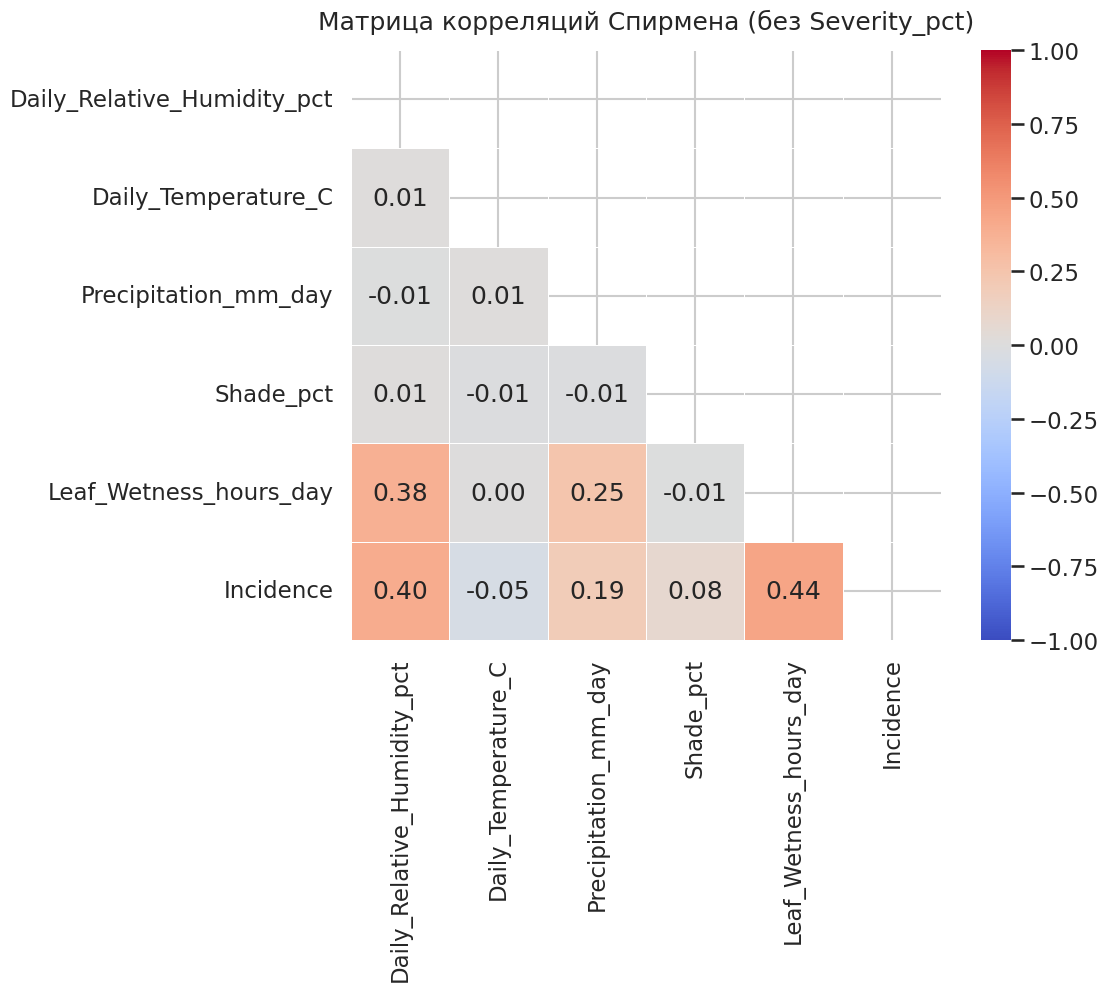

In [67]:
df_corr = df[['Daily_Relative_Humidity_pct', 'Daily_Temperature_C', 'Precipitation_mm_day',
             'Shade_pct', 'Leaf_Wetness_hours_day', 'Incidence']]

# 2. Считаем матрицу корреляций Спирмена (устойчивее к нелинейностям)
corr_matrix = df_corr.corr(method="spearman")

# 3. Строим общую матрицу (Heatmap)
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Скрываем верхний треугольник для красоты
sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", vmin=-1, vmax=1,
            annot=True, fmt=".2f", square=True, linewidths=.5, ax=ax)
ax.set_title("Матрица корреляций Спирмена (без Severity_pct)", pad=15)
plt.tight_layout()
plt.savefig("fig_corr_heatmap.png", dpi=150)
plt.show()

По коэффициентам корреляции можно сказать, что **наибольшее влияние на заражение кофейной ржавчиной оказывает часы влажности и относительная влажность воздуха - значения 0.44 и 0.40 соответственно.** Связь умеренная положительная, с ростом одного показателя растет другой. Также показатель часов влажности связан с влажностью воздуха (коэффициент 0.38) и осадками (0.25). Они напрямую влияют на длительность нахождения свободной влаги на листе, как обсуждалось выше.



### Coffee_variety

Сорта по отношению к болезни могут быть устойчивыми или восприимчивыми. Устойчивые сорта кофейного дерева в основном гибриды, что связано с их природным иммунитетом.

In [68]:
df['Coffee_variety'].value_counts()

,count
Coffee_variety,
Ruiru11,2894
SL28,2531
Other,1974
SL34,1437
Batian,1014


В нашем наборе данных есть следующие сорта
* сорт Руиру (Ruiru11) и Батиан (Batian) - устойчивые гибриды с генами робусты и тимора.
* SL28 и SL34 - восприимчивые сорта, но обладают ценными вкусовыми качествами.
* Other - другие.

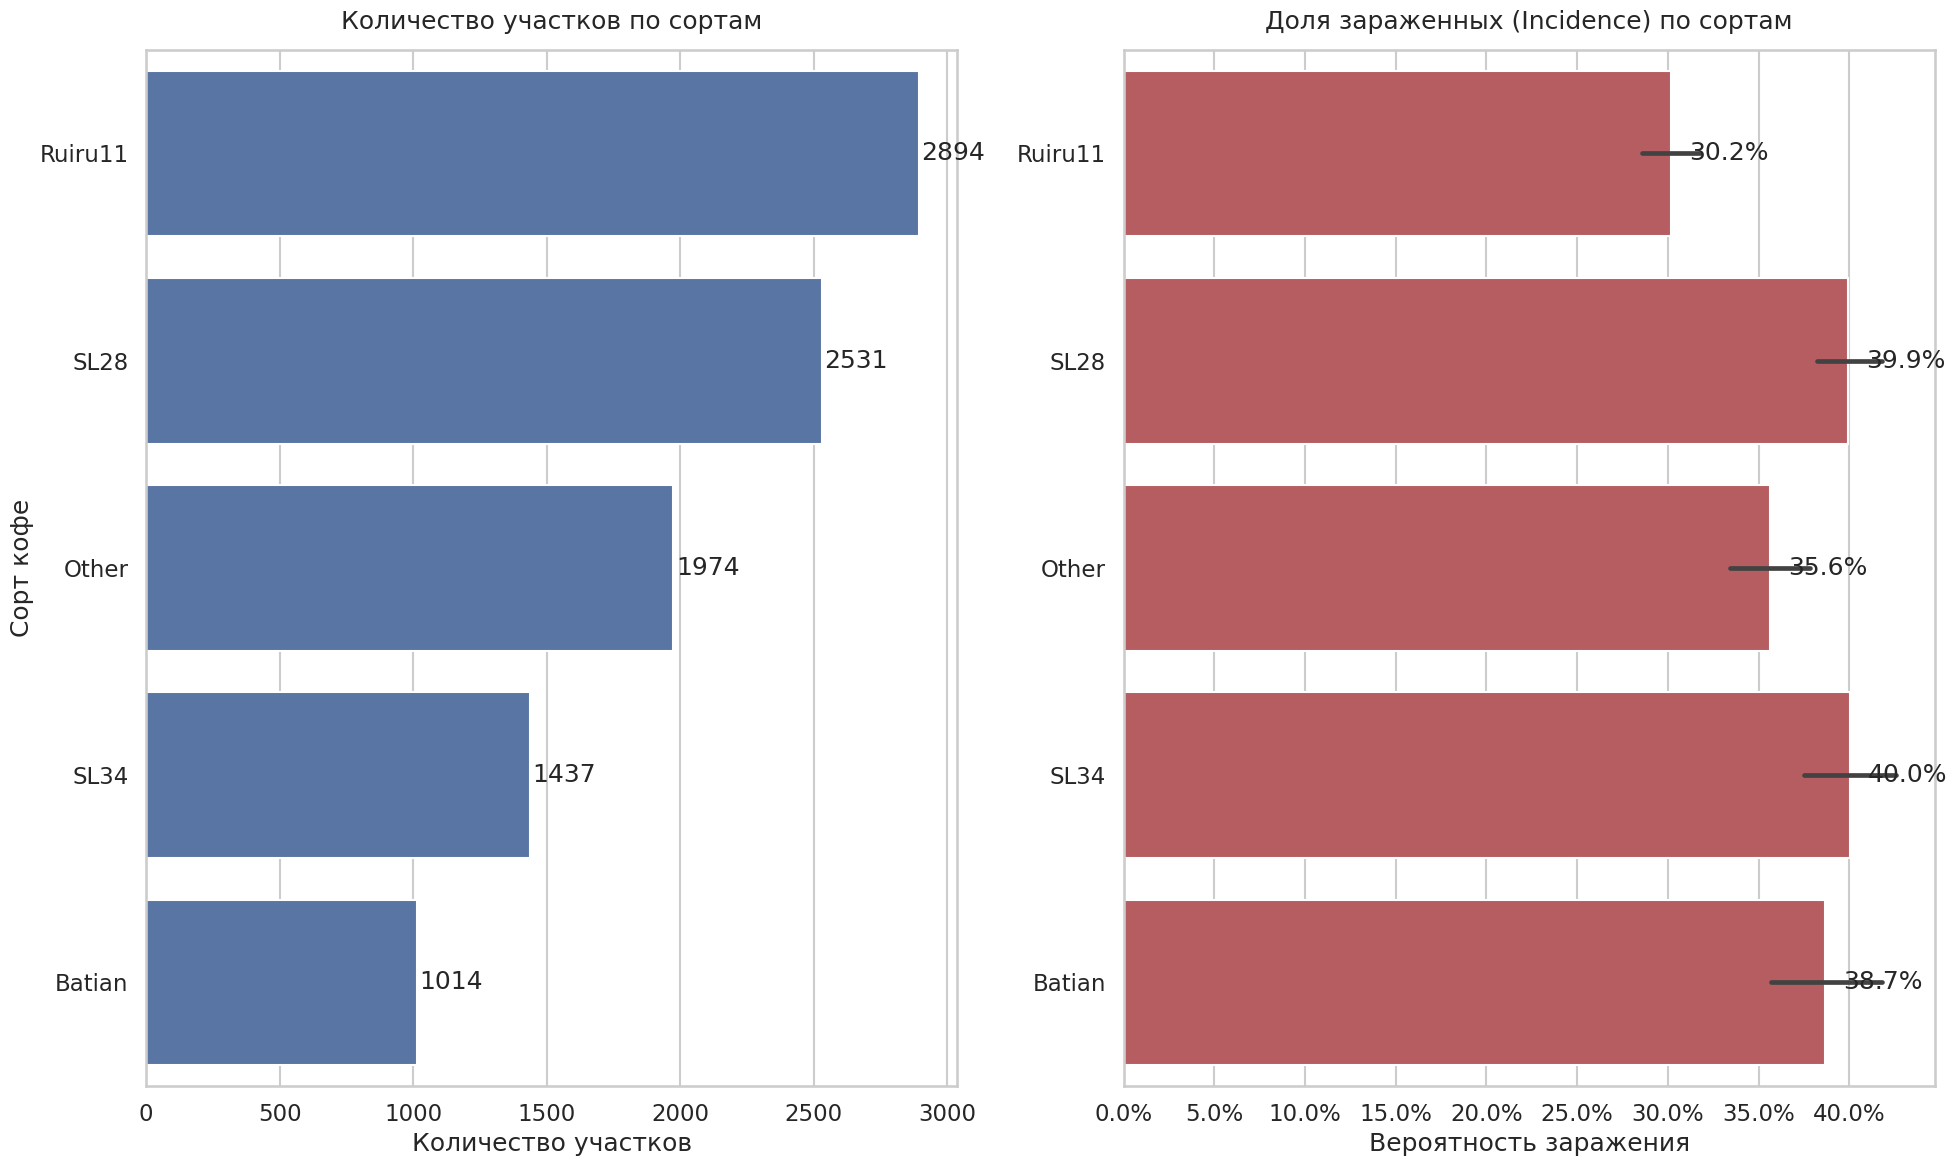

In [69]:
# 1. Распределение сортов и доля заражения
fig, axes = plt.subplots(1, 2, figsize=(20, 12))

# Левый график: Количество участков по сортам
order_variety = df["Coffee_variety"].value_counts().index
sns.countplot(data=df, y="Coffee_variety", order=order_variety,
              color="#4C72B0", ax=axes[0])
axes[0].set_title("Количество участков по сортам", pad=15)
axes[0].set_xlabel("Количество участков")
axes[0].set_ylabel("Сорт кофе")

# Добавим подписи с цифрами
for i, p in enumerate(axes[0].patches):
    axes[0].text(p.get_width() + 10, p.get_y() + p.get_height()/2,
                 f'{int(p.get_width())}', va='center')

# Правый график: Доля зараженных по сортам (с 95% CI)
sns.barplot(data=df, y="Coffee_variety", x="Incidence",
            order=order_variety, errorbar=('ci', 95),
            color="#C44E52", ax=axes[1])
axes[1].set_title("Доля зараженных (Incidence) по сортам", pad=15)
axes[1].set_xlabel("Вероятность заражения")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

# Добавим подписи с процентами
for i, p in enumerate(axes[1].patches):
    axes[1].text(p.get_width() + 0.01, p.get_y() + p.get_height()/2,
                 f'{p.get_width():.1%}', va='center')

plt.tight_layout()
plt.savefig("fig_variety_incidence.png", dpi=150)
plt.show()

Больше всего участков с сортом Руиру. В целом устойчивые сорта занимают около 40% записей, как и восприимчивые сорта.

По графику видно, что доверительные интервалы не пересекаются за счет больших выборок, значит, у нас есть статистически значимые различия в риске заражения между сортами. **Наименьший риск у утойчивого к кофейной ржавчине сорта Руиру (30.2%). У восприимчивых сортов SL34 и SL28 риск наибольший (40%).** При этом сорт Батиан, описанный в литературе как устойчивый, показывает риск в 38.7%.

Разница в риске между сортами меньше, чем между климатическими факторами, которые были рассмотрены выше. Устойчивые сорта не могут гарантировать полное отсутствие болезни особенно при благоприятных условиях для развития патогена, но такие растения могут меньше поражаться, что способствует сохранению урожая.

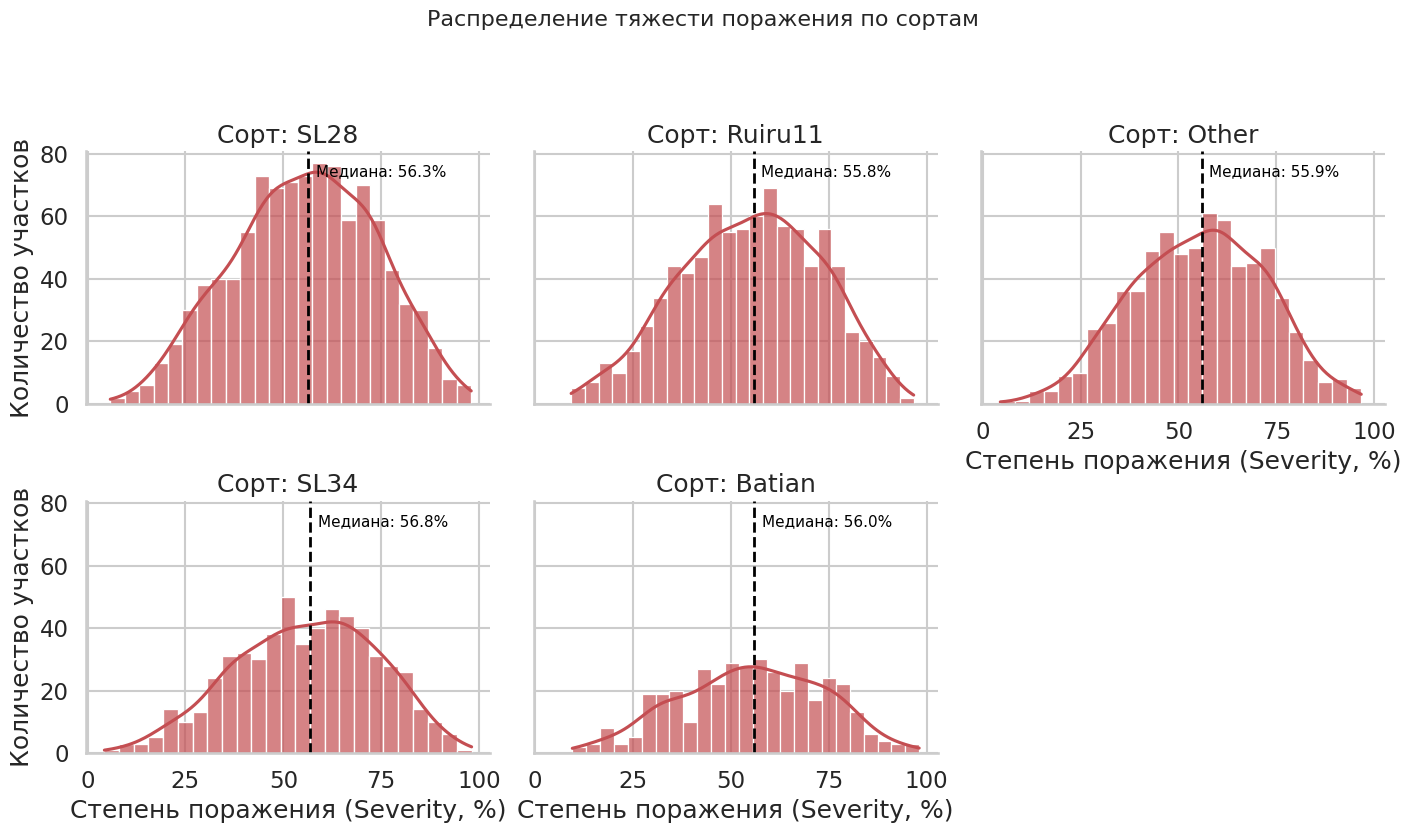

In [70]:
# 1. Фильтруем данные: оставляем только зараженные участки
df_infected = df[df["Incidence"] == 1].copy()

# 2. Строим сетку гистограмм (FacetGrid)
# col_wrap=3 означает, что будет 3 колонки, а остальные перенесутся на второй ряд
g = sns.FacetGrid(df_infected, col="Coffee_variety", col_wrap=3,
                  height=4, aspect=1.2, sharex=True, sharey=True)

# Рисуем гистограмму с KDE (линией плотности) для каждой ячейки
g.map(sns.histplot, "Severity_pct", bins=25, color="#C44E52", kde=True, alpha=0.7)

# Добавляем медиану на каждый график
for ax, variety in zip(g.axes.flat, df_infected["Coffee_variety"].unique()):
    # Считаем медиану для конкретного сорта
    median_val = df_infected[df_infected["Coffee_variety"] == variety]["Severity_pct"].median()

    # Рисуем вертикальную линию
    ax.axvline(median_val, color="black", linestyle="--", linewidth=2)

    # Добавляем текст с медианой
    ax.text(median_val + 2, ax.get_ylim()[1] * 0.9,
            f"Медиана: {median_val:.1f}%",
            color="black", fontsize=11, rotation=0)

# Настраиваем заголовки
g.set_axis_labels("Степень поражения (Severity, %)", "Количество участков")
g.set_titles("Сорт: {col_name}")
g.fig.suptitle("Распределение тяжести поражения по сортам",
               y=1.05, fontsize=16)

plt.tight_layout()
plt.savefig("fig_severity_hist_by_variety.png", dpi=150)
plt.show()

Распределения сортов по проценту пораженности почти идентичны и медиана у всех сортов около 56%. Возможно, на степень пораженности больше повлияли другие факторы.

Таким образом, генетическая устойчивость сортов влияет на вероятность заражения, но не влияет на степень пораженности. Если растение заразилось, то болезгь протекает одинаково и устойчивых, и восприимчивых сортов.

### Fungicide_use & Fungicide_freq_per_season

Фунгициды могут быть использованы в профилактических и в лечебных целях. Так, фунгицид могли использовать и до поражения (например участки, где уже была вспышка или где есть восприимчивые сорта) и после с целью остановления развития болезни и распространения патогена. Но если степень поражения слишком высокая использование препаратов может быть уже экономически невыгодным. Или если степень пораженности низкая можно не использовать химическую защиту - потери урожая будут не такими высокими, как затраты на применение фунгицидов (закупка, транспортировка, опрыскивание и пр).

Экономическим порогом вредоносности (ЭПВ) для кофейной ржавчины является 5-10% поражения на растении.

Частота использования фунгицидов может зависеть от степени поражения или от самого препарата.

Сначала посмотрим как применение фунгцидов связано с риском заражения

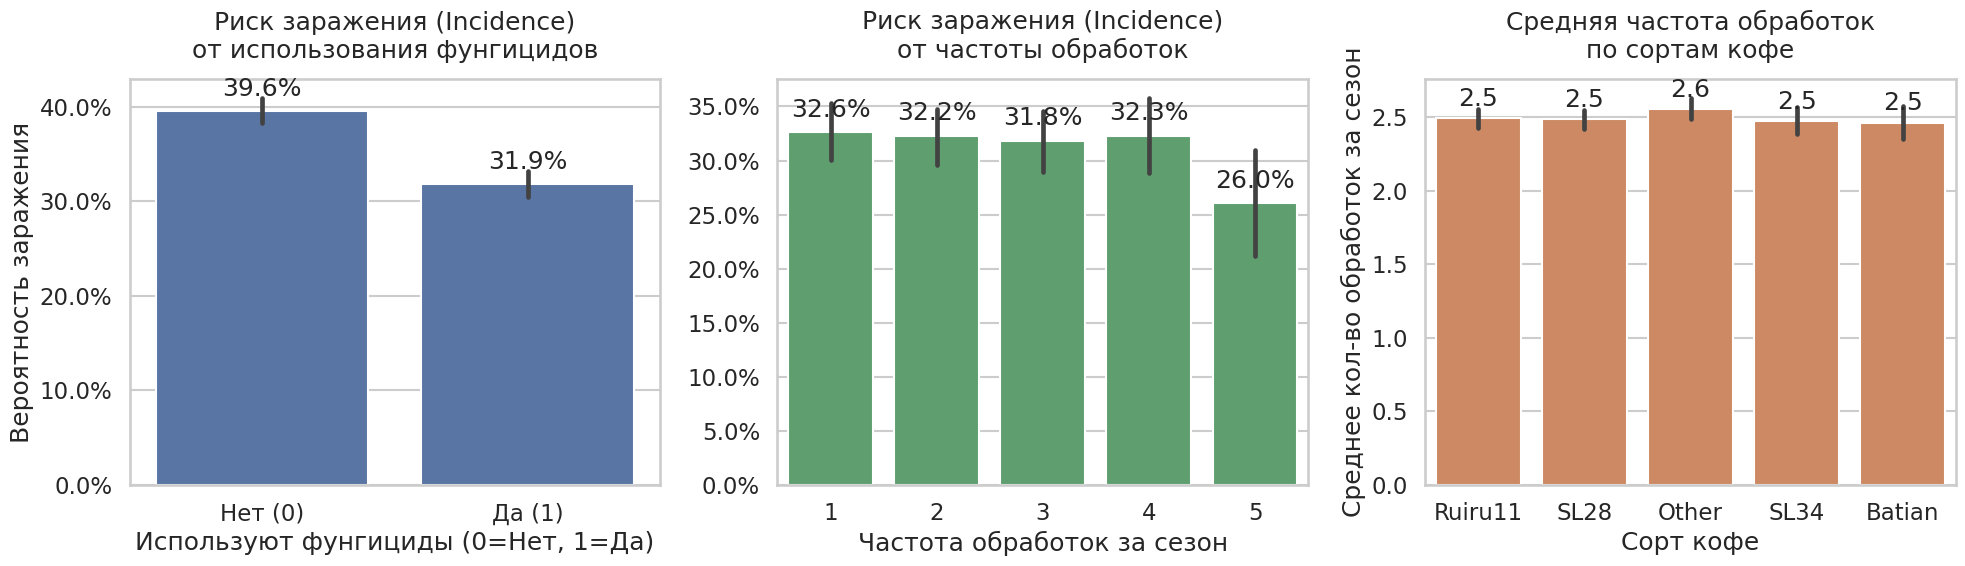

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Использование фунгицидов и риск заражения (Incidence)
sns.barplot(data=df, x="Fungicide_use", y="Incidence",
            ax=axes[0], color="#4C72B0", errorbar=('ci', 95))
axes[0].set_title("Риск заражения (Incidence)\nот использования фунгицидов", pad=15)
axes[0].set_xlabel("Используют фунгициды (0=Нет, 1=Да)")
axes[0].set_ylabel("Вероятность заражения")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Нет (0)", "Да (1)"])
# Подписи значений
for i, p in enumerate(axes[0].patches):
    axes[0].text(p.get_x() + p.get_width()/2, p.get_height() + 0.01,
                 f'{p.get_height():.1%}', ha='center', va='bottom')


# 2. Частота обработок и риск заражения
# Фильтруем только тех, кто использует фунгициды
df_freq = df[df["Fungicide_use"] == 1].copy()

sns.barplot(data=df_freq, x="Fungicide_freq_per_season", y="Incidence",
            ax=axes[1], color="#55A868", errorbar=('ci', 95))
axes[1].set_title("Риск заражения (Incidence)\nот частоты обработок", pad=15)
axes[1].set_xlabel("Частота обработок за сезон")
axes[1].set_ylabel("")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for i, p in enumerate(axes[1].patches):
    axes[1].text(p.get_x() + p.get_width()/2, p.get_height() + 0.01,
                 f'{p.get_height():.1%}', ha='center', va='bottom')


# 3. Как часто применяют обработки на разных сортах
order_variety = df_freq["Coffee_variety"].value_counts().index
sns.barplot(data=df_freq, x="Coffee_variety", y="Fungicide_freq_per_season",
            order=order_variety, ax=axes[2], color="#DD8452", errorbar=('ci', 95))
axes[2].set_title("Средняя частота обработок\nпо сортам кофе", pad=15)
axes[2].set_xlabel("Сорт кофе")
axes[2].set_ylabel("Среднее кол-во обработок за сезон")

for i, p in enumerate(axes[2].patches):
    axes[2].text(p.get_x() + p.get_width()/2, p.get_height() + 0.05,
                 f'{p.get_height():.1f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("fig_fungicide_part1_incidence.png", dpi=150)
plt.show()

Риск заражения кофейной ржавчиной выше там, где не используют фунгициды вообще (40%). Это может говорить о значимости профилактических мер. Там, где применялись обработки риск 32%. Это в среднем ниже, чем риск по всему датасету. Так, если использовать фунгициды в профилактических целях, можно снизить риск заражения почти на 8%.

По второму графику можно сказать, что при количестве обработок от 1 до 4 риск заражения одинаков (около 32%), однако при 5 обработках риск падает до 26%. Однако, доверительные интервалы на этих данных перекрываются с другими (таких данных меньше, мы не можем быть полностью уверены, что это не случайность). Так, нет смысла тратить ресурсы на количество обработок менее 5 и более 1. При одной обработке риск все равно ниже, чем если вообще не применять фунгициды (риск понижается на 8%).

На сортах фунгицидные обработки применяли одинаково, среднее количество обработок 2.5. Возможно, так делали для создания одинаковых условий.

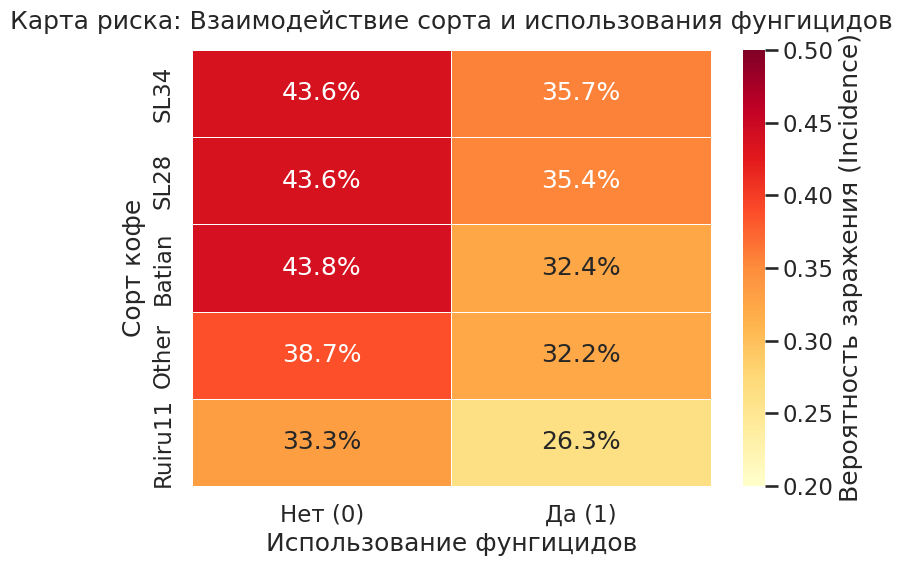

In [72]:
# 1. Создаем сводную таблицу (pivot): строки - сорта, столбцы - использование фунгицидов
pivot_fung_variety = df.pivot_table(
    index="Coffee_variety",
    columns="Fungicide_use",
    values="Incidence",
    aggfunc="mean"
)

# Упорядочим строки так же, как на предыдущих графиках (по убыванию уязвимости)
order = ["SL34", "SL28", "Batian", "Other", "Ruiru11"]
pivot_fung_variety = pivot_fung_variety.reindex(order)

# 2. Рисуем тепловую карту
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(pivot_fung_variety, annot=True, fmt=".1%", cmap="YlOrRd",
            linewidths=.5, cbar_kws={'label': 'Вероятность заражения (Incidence)'},
            ax=ax, vmin=0.2, vmax=0.5) # Задаем vmin/vmax, чтобы цвет был контрастнее

ax.set_title("Карта риска: Взаимодействие сорта и использования фунгицидов", pad=15)
ax.set_xlabel("Использование фунгицидов")
ax.set_ylabel("Сорт кофе")

# Меняем подписи по оси X с 0.0 и 1.0 на текст
ax.set_xticklabels(["Нет (0)", "Да (1)"])

plt.tight_layout()
plt.savefig("fig_heatmap_variety_fungicide.png", dpi=150)
plt.show()

В целом, на всех сортах падает риск заражения при использовании фунгицидов. На устойчивом сорте Руиру риск падает до 26% - самый низкий показатель среди всех сортов. На восприимчивых сортах риск падает на 8% до 35%. Сорт Батиан при этом имеет риск заражения при отсутствии обработок такой же, как и восприимчивые сорта. Это говорит о эффективности применения фунгицидов

Изучим связь применения химической защиты и степени пораженности

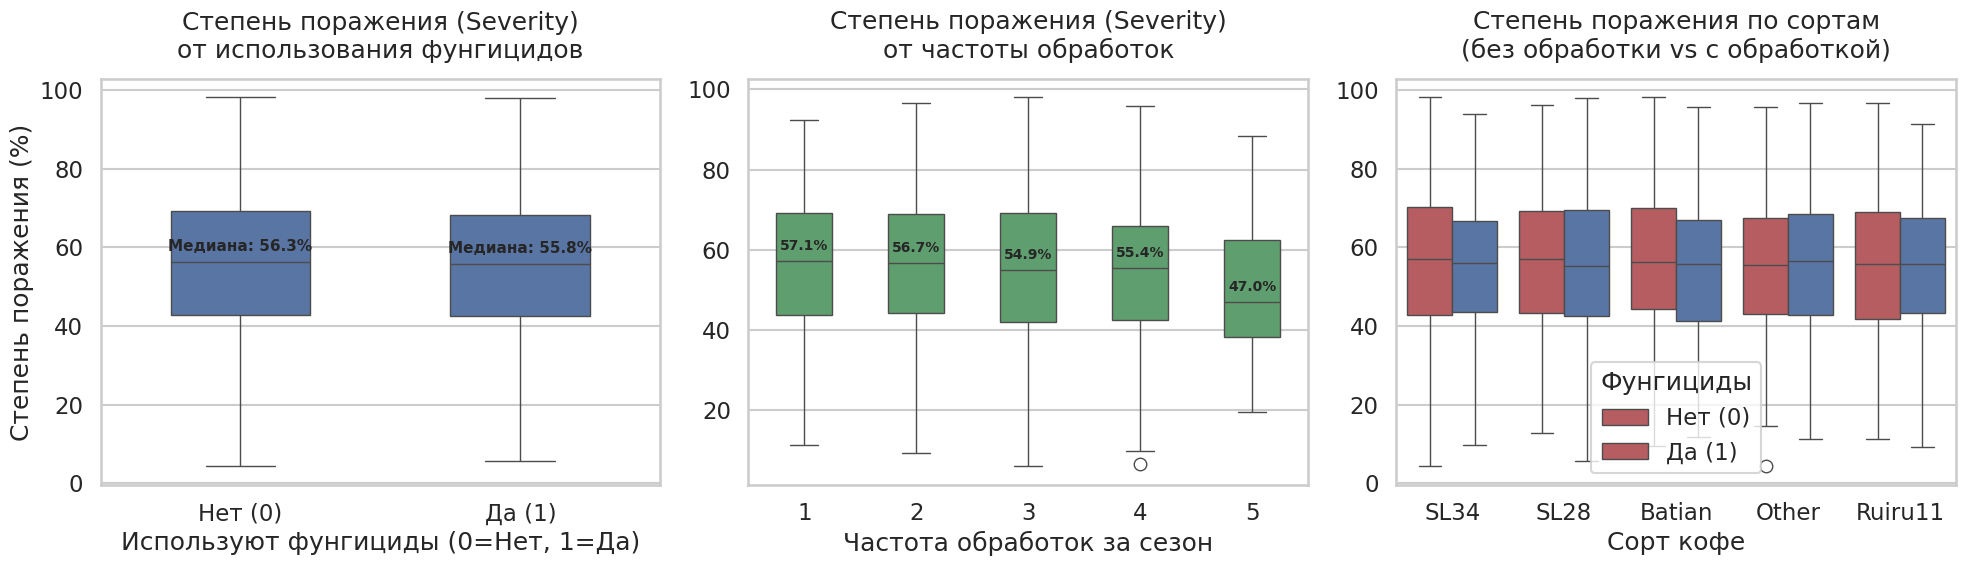

In [73]:
df_infected = df[df["Incidence"] == 1].copy()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Использование фунгицидов и Степень поражения (Severity)
sns.boxplot(data=df_infected, x="Fungicide_use", y="Severity_pct",
            ax=axes[0], color="#4C72B0", width=0.5)
axes[0].set_title("Степень поражения (Severity)\nот использования фунгицидов", pad=15)
axes[0].set_xlabel("Используют фунгициды (0=Нет, 1=Да)")
axes[0].set_ylabel("Степень поражения (%)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Нет (0)", "Да (1)"])

# Добавим медианы текстом для наглядности
medians_use = df_infected.groupby("Fungicide_use")["Severity_pct"].median()
for i, (use_val, median_val) in enumerate(medians_use.items()):
    axes[0].text(i, median_val + 2, f"Медиана: {median_val:.1f}%",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')


# 2. Частота обработок и Степень поражения
# Фильтруем только тех, кто использует фунгициды
df_freq_inf = df_infected[df_infected["Fungicide_use"] == 1].copy()

sns.boxplot(data=df_freq_inf, x="Fungicide_freq_per_season", y="Severity_pct",
            ax=axes[1], color="#55A868", width=0.5)
axes[1].set_title("Степень поражения (Severity)\nот частоты обработок", pad=15)
axes[1].set_xlabel("Частота обработок за сезон")
axes[1].set_ylabel("")
axes[1].set_xticks(range(5))
axes[1].set_xticklabels(["1", "2", "3", "4", "5"])

# Добавим медианы текстом
medians_freq = df_freq_inf.groupby("Fungicide_freq_per_season")["Severity_pct"].median()
for i, median_val in enumerate(medians_freq):
    axes[1].text(i, median_val + 2, f"{median_val:.1f}%",
                 ha='center', va='bottom', fontsize=10, fontweight='bold')


# 3. Степень поражения по сортам (с учетом обработок)
order_variety = ["SL34", "SL28", "Batian", "Other", "Ruiru11"]
sns.boxplot(data=df_infected, x="Coffee_variety", y="Severity_pct",
            hue="Fungicide_use", order=order_variety, ax=axes[2],
            palette={0: "#C44E52", 1: "#4C72B0"})
axes[2].set_title("Степень поражения по сортам\n(без обработки vs с обработкой)", pad=15)
axes[2].set_xlabel("Сорт кофе")
axes[2].set_ylabel("")
axes[2].legend(title="Фунгициды", labels=["Нет (0)", "Да (1)"])

plt.tight_layout()
plt.savefig("fig_fungicide_part2_severity.png", dpi=150)
plt.show()

Из графиков видно, что фунгицидные обработки не сильно влияют на степень поражения. Единственное заметное различие - степень поражения ниже при количестве обработок равным 5. Медиана будет 47% против 55-57% у обработок 1-4. Частые обработки могут эффективно подавить патоген.

Так, если растение уже заразилось эффективность фунгицидов падает. **Следует использовать фунгициды в профилактических целях для предотвращения заражения**, что соответствует главному принципу интегрированной защиты растений - минимизация химических мероприятий (использовать химические препараты в крайних случаях). Риск заражения и степень поражения ниже при 5 обработках, но это требует дополнительной проверки, так как таких данных мало.

Сейчас посмотрим на связь применения фунгицидов и возраста растений.

Кофейные деревья начинают плодоносить в 2–4 года, выходят на пик продуктивности к 5–7 годам, а экономически продуктивны до 25–30 лет.

/tmp/ipykernel_6744/2058922864.py:49: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_age = df.pivot_table(index="Age_Group", columns="Fungicide_use", values="Incidence", aggfunc="mean")


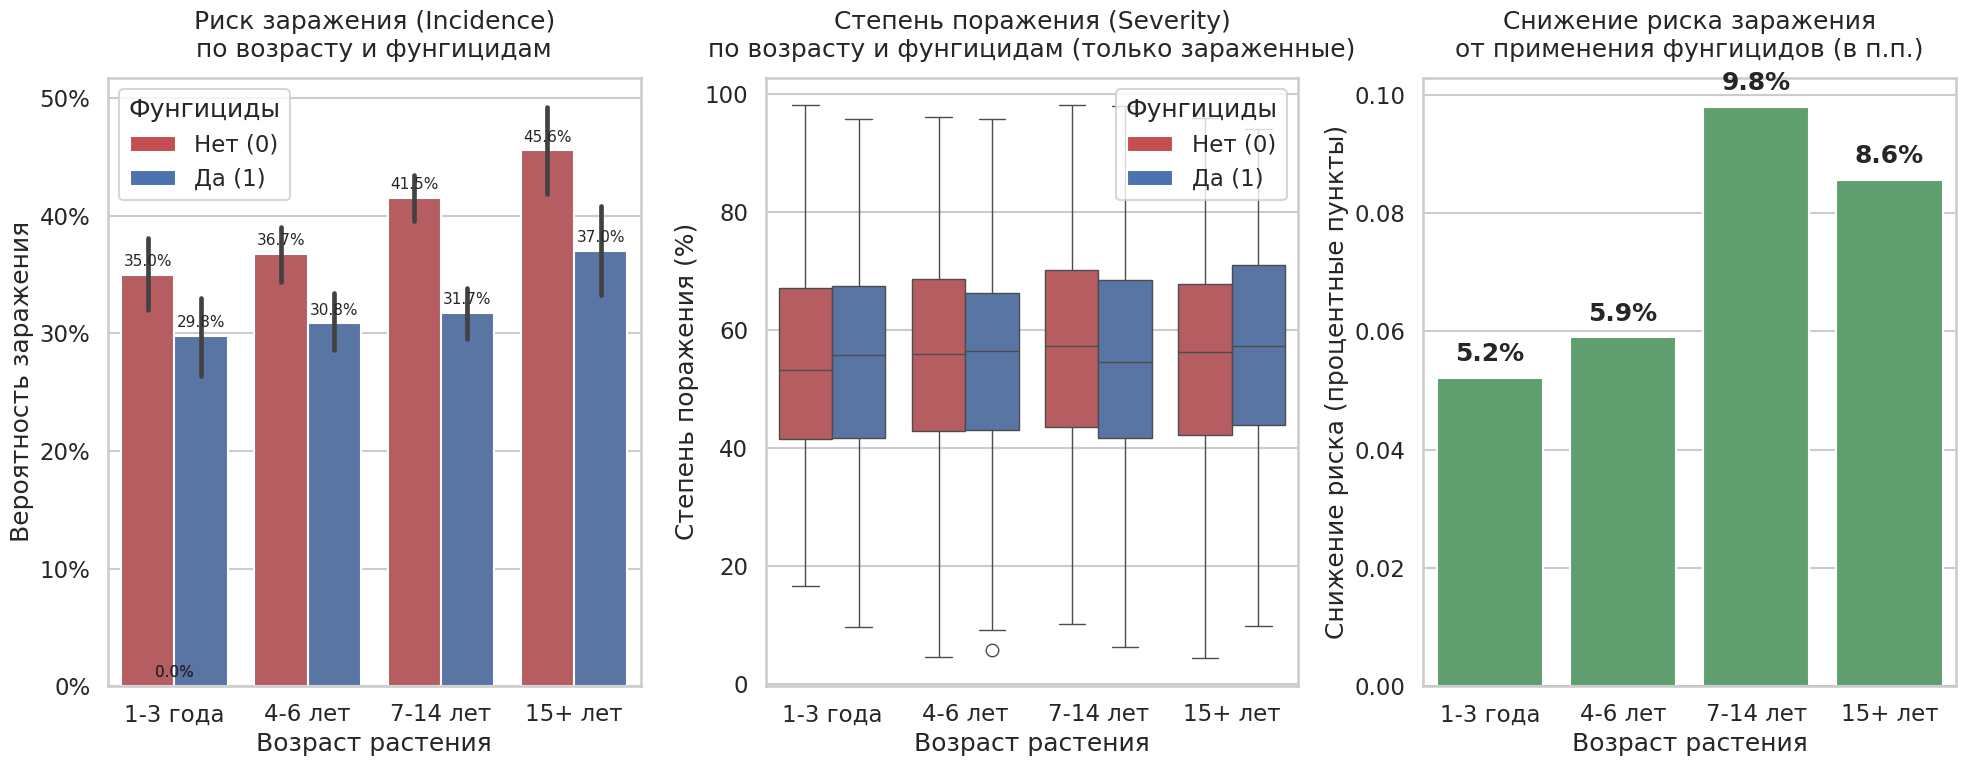

In [74]:
sns.set_theme(style="whitegrid", context="talk")

# 1. Создаем возрастные группы
df['Age_Group'] = pd.cut(
    df['Plant_age_years'],
    bins=[0, 3, 6, 14, 100],
    labels=['1-3 года', '4-6 лет', '7-14 лет', '15+ лет'],
    include_lowest=True
)

# 2. Создаем полотно 1x3
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Создаем кастомную легенду (цвета берем ровно те, что в palette)
legend_elements = [
    Patch(facecolor='#C44E52', label='Нет (0)'),
    Patch(facecolor='#4C72B0', label='Да (1)')
]


# ГРАФИК 1: Риск заражения (Incidence) по возрасту и фунгицидам
sns.barplot(data=df, x="Age_Group", y="Incidence", hue="Fungicide_use",
            ax=axes[0], palette={0: "#C44E52", 1: "#4C72B0"}, errorbar=('ci', 95))
axes[0].set_title("Риск заражения (Incidence)\nпо возрасту и фунгицидам", pad=15)
axes[0].set_xlabel("Возраст растения")
axes[0].set_ylabel("Вероятность заражения")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
# ИСПОЛЬЗУЕМ КАСТОМНУЮ ЛЕГЕНДУ
axes[0].legend(handles=legend_elements, title="Фунгициды", loc="upper left")

for i, p in enumerate(axes[0].patches):
    axes[0].text(p.get_x() + p.get_width()/2, p.get_height() + 0.005,
                 f'{p.get_height():.1%}', ha='center', va='bottom', fontsize=11)

# ГРАФИК 2: Степень поражения (Severity) по возрасту и фунгицидам
df_infected = df[df["Incidence"] == 1]

sns.boxplot(data=df_infected, x="Age_Group", y="Severity_pct", hue="Fungicide_use",
            ax=axes[1], palette={0: "#C44E52", 1: "#4C72B0"})
axes[1].set_title("Степень поражения (Severity)\nпо возрасту и фунгицидам (только зараженные)", pad=15)
axes[1].set_xlabel("Возраст растения")
axes[1].set_ylabel("Степень поражения (%)")
# ИСПОЛЬЗУЕМ КАСТОМНУЮ ЛЕГЕНДУ
axes[1].legend(handles=legend_elements, title="Фунгициды", loc="upper right")

# ГРАФИК 3: Эффективность фунгицидов (Разница в риске)
pivot_age = df.pivot_table(index="Age_Group", columns="Fungicide_use", values="Incidence", aggfunc="mean")
pivot_age["Efficiency"] = pivot_age[0] - pivot_age[1]

sns.barplot(x=pivot_age.index, y=pivot_age["Efficiency"],
            ax=axes[2], color="#55A868")
axes[2].set_title("Снижение риска заражения\nот применения фунгицидов (в п.п.)", pad=15)
axes[2].set_xlabel("Возраст растения")
axes[2].set_ylabel("Снижение риска (процентные пункты)")
axes[2].axhline(0, color="black", linewidth=1)

for i, p in enumerate(axes[2].patches):
    axes[2].text(p.get_x() + p.get_width()/2, p.get_height() + 0.002,
                 f'{p.get_height():.1%}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("fig_age_fungicide_analysis.png", dpi=150)
plt.show()

Возраст растения влияет на эффективность применения обработок. Наиболее высокий риск поражения у деревьев возрастом выше 15 лет при отсутствии обработок. Больше всего риск заражения снижается у растений возрастом 7-14 лет при прменении фунгицидов. Следовательно, наибольшая эффективность фунгицидов достигается при обработках растений полновозрастных. У таких деревьев крона становится гуще, что может создавать благоприятные условия для патогена (тень, свободная влага не испаряется). У стареющих деревьев эффективность немного ниже. На плантациях с такими деревьями уже может быть накопленный высокий инфекционный фон из-за чего применение обработок не так эффективно.

**Так, особое внимание надо уделить деревьям в возрасте от 7 лет. Фунгициды наиболее эффективны на образцах 7-14 лет.**

### Past_outbreak_history & Lagged_incidence_prev_week

История вспышек говорит о инфекционном фоне на участке. Если вспышка была, накопленный инфекционный фон будет высоким. У ржавчины главным источником ифекции являются листья.

Лаговая заболеваемость - показатель, который мог бы быть полезен при наличии дат для анализа временных рядов (например, для изучения агрессивности и скорости развития патогена - провести анализ относительно степени пораженности). Однако, интуитивно ясно: если появились образцы пораженные на прошлой неделе, то на этой неделе тоже появятся новые. Тем более период инкубации у патогена кофейной ржавчины 4-6 недель - знания о новых признаках малоинформативны. Заражение могло произойти еще давно, а симптомы на разных растениях могут задержаться в проявлении.

Связь признаков с риском заражения

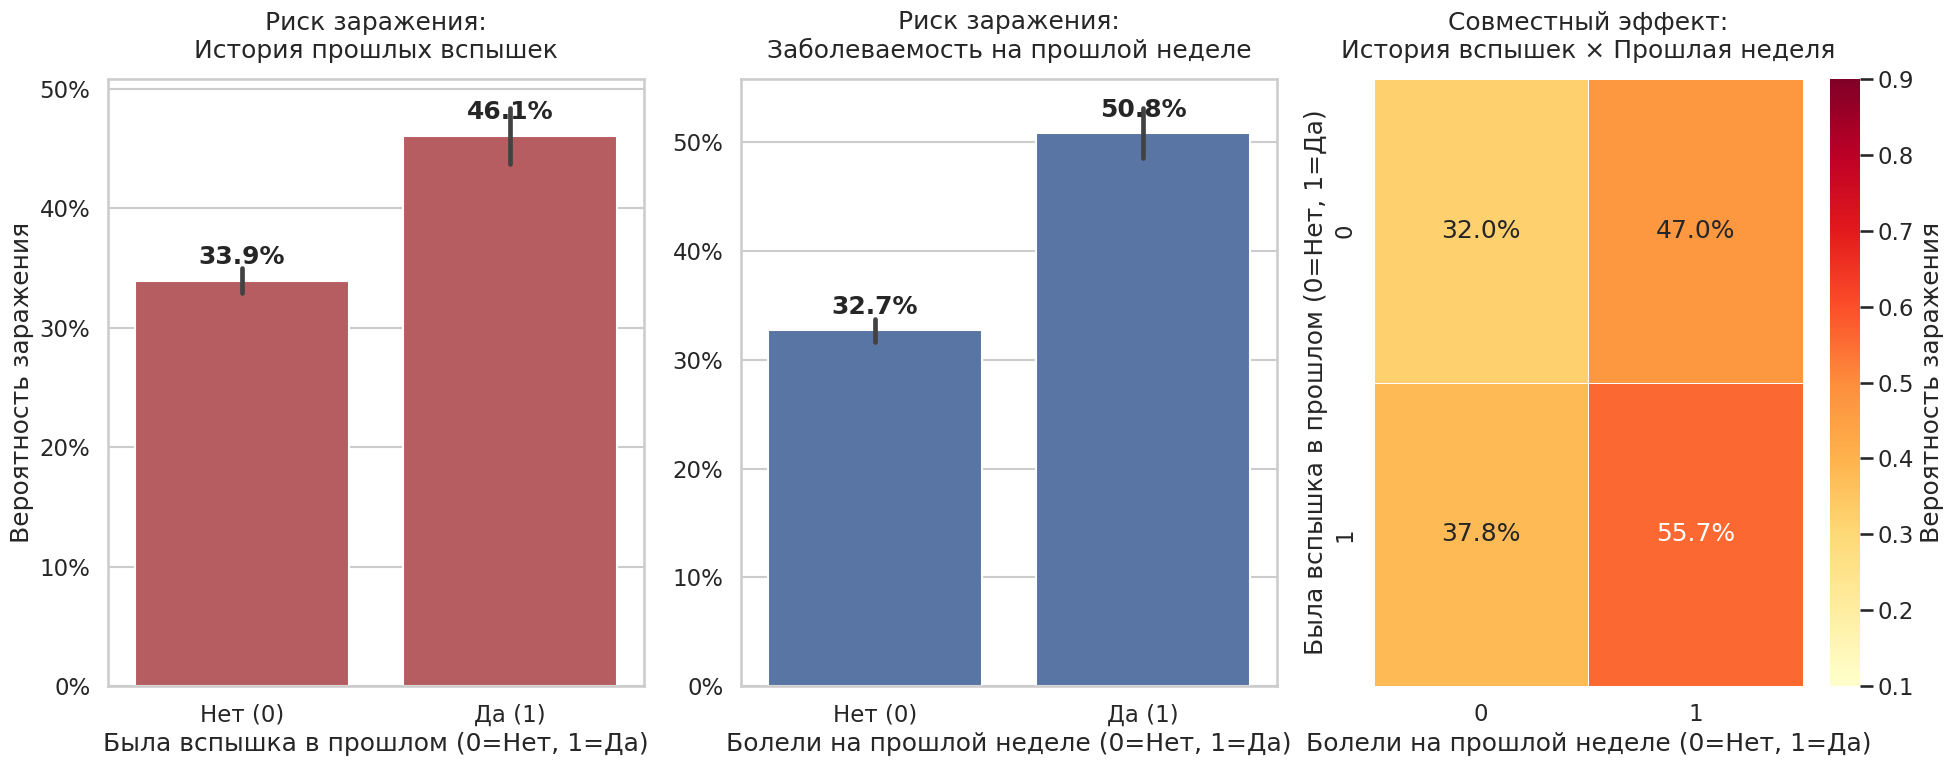

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Кастомная легенда для единообразия
legend_elements = [Patch(facecolor='#4C72B0', label='Нет (0)'),
                   Patch(facecolor='#C44E52', label='Да (1)')]


# 1. Риск от истории прошлых вспышек
sns.barplot(data=df, x="Past_outbreak_history", y="Incidence",
            ax=axes[0], color="#C44E52", errorbar=('ci', 95))
axes[0].set_title("Риск заражения:\nИстория прошлых вспышек", pad=15)
axes[0].set_xlabel("Была вспышка в прошлом (0=Нет, 1=Да)")
axes[0].set_ylabel("Вероятность заражения")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Нет (0)", "Да (1)"])

for i, p in enumerate(axes[0].patches):
    axes[0].text(p.get_x() + p.get_width()/2, p.get_height() + 0.01,
                 f'{p.get_height():.1%}', ha='center', va='bottom', fontweight='bold')


# 2. Риск от заболеваемости на прошлой неделе (Lagged)
sns.barplot(data=df, x="Lagged_incidence_prev_week", y="Incidence",
            ax=axes[1], color="#4C72B0", errorbar=('ci', 95))
axes[1].set_title("Риск заражения:\nЗаболеваемость на прошлой неделе", pad=15)
axes[1].set_xlabel("Болели на прошлой неделе (0=Нет, 1=Да)")
axes[1].set_ylabel("")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Нет (0)", "Да (1)"])

for i, p in enumerate(axes[1].patches):
    axes[1].text(p.get_x() + p.get_width()/2, p.get_height() + 0.01,
                 f'{p.get_height():.1%}', ha='center', va='bottom', fontweight='bold')

# 3. Совместный эффект (Heatmap)
# Строим сводную таблицу
pivot_hist_lag = df.pivot_table(index="Past_outbreak_history",
                                columns="Lagged_incidence_prev_week",
                                values="Incidence", aggfunc="mean")

sns.heatmap(pivot_hist_lag, annot=True, fmt=".1%", cmap="YlOrRd",
            linewidths=.5, cbar_kws={'label': 'Вероятность заражения'},
            ax=axes[2], vmin=0.1, vmax=0.9)

axes[2].set_title("Совместный эффект:\nИстория вспышек × Прошлая неделя", pad=15)
axes[2].set_xlabel("Болели на прошлой неделе (0=Нет, 1=Да)")
axes[2].set_ylabel("Была вспышка в прошлом (0=Нет, 1=Да)")

plt.tight_layout()
plt.savefig("fig_history_lag_incidence.png", dpi=150)
plt.show()

По графикам видно, что при наличии вспышек и наличии заболеваемости на прошлой неделе риск выше, чем при отсутствии этих факторов. Они равны 46% и 50.8%. Однако при взаимодействии и наличии этих двух факторов одновременно риск растет до 55.7%. Наибольший вклад дает именно лаговая заболеваемость.

Так, **особое внимание надо уделят участкам, на которых уже была вспышка ввиду высокого инфекционного фона, когда только проявились первые симптомы кофейной ржавчины - это может привести к новой вспышке.** Но ждать пока проявятся первые пораженные растения не стоит, нужно проводить на таких участках профилактические фунгицидные обработки (в первую очередь всё-таки тщательно проводить уборку опавших листьев, споры сохраняются на листьях в течение 4-6 недель).

Связь с степенью поражения

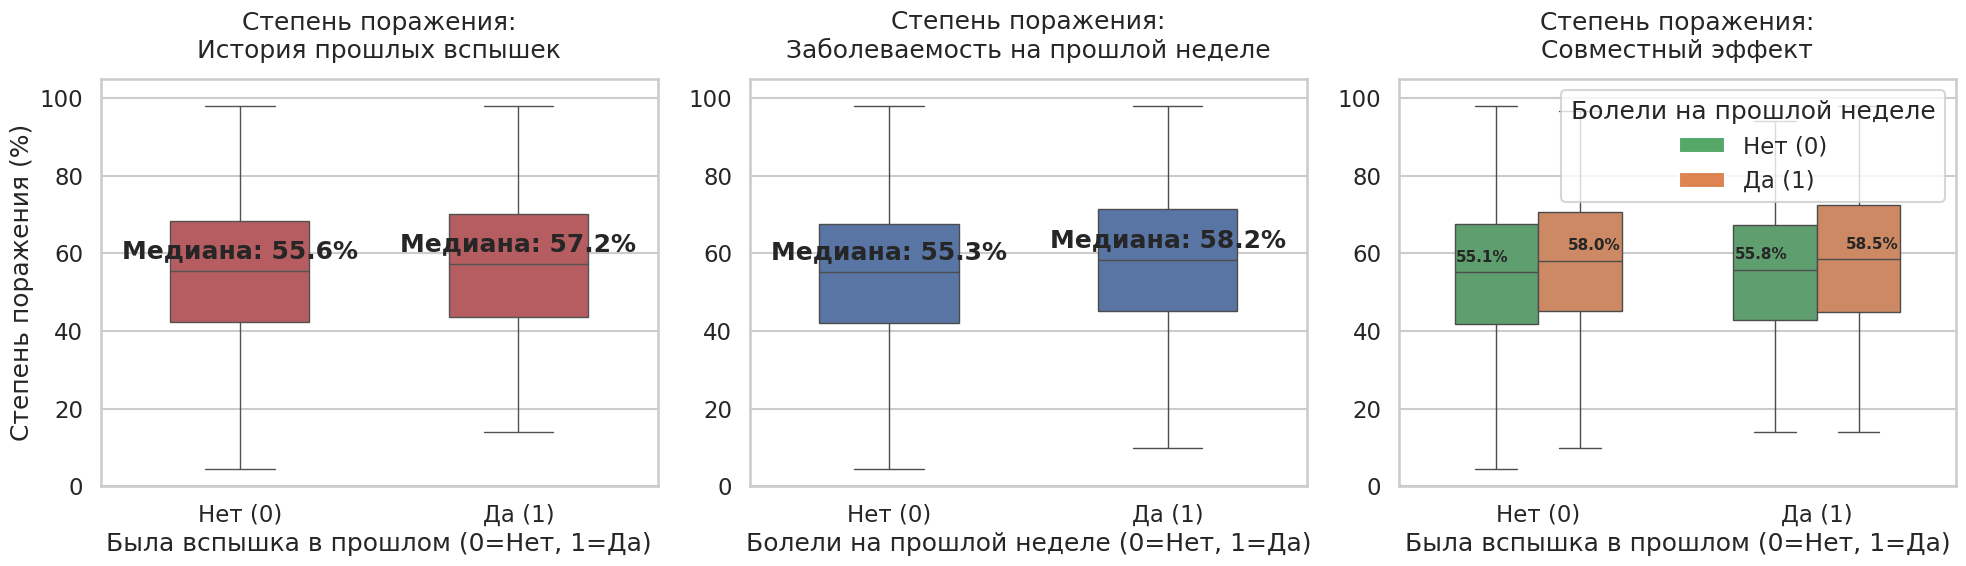

In [76]:
# Фильтруем только зараженные
df_infected = df[df["Incidence"] == 1].copy()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Severity от истории прошлых вспышек
sns.boxplot(data=df_infected, x="Past_outbreak_history", y="Severity_pct",
            ax=axes[0], color="#C44E52", width=0.5)
axes[0].set_title("Степень поражения:\nИстория прошлых вспышек", pad=15)
axes[0].set_xlabel("Была вспышка в прошлом (0=Нет, 1=Да)")
axes[0].set_ylabel("Степень поражения (%)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Нет (0)", "Да (1)"])

# Добавляем медианы текстом
medians_0 = df_infected.groupby("Past_outbreak_history")["Severity_pct"].median()
for i, val in enumerate(medians_0):
    axes[0].text(i, val + 2, f"Медиана: {val:.1f}%", ha="center", va="bottom", fontweight='bold')

# 2. Severity от прошлой недели
sns.boxplot(data=df_infected, x="Lagged_incidence_prev_week", y="Severity_pct",
            ax=axes[1], color="#4C72B0", width=0.5)
axes[1].set_title("Степень поражения:\nЗаболеваемость на прошлой неделе", pad=15)
axes[1].set_xlabel("Болели на прошлой неделе (0=Нет, 1=Да)")
axes[1].set_ylabel("")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Нет (0)", "Да (1)"])

# Добавляем медианы текстом
medians_1 = df_infected.groupby("Lagged_incidence_prev_week")["Severity_pct"].median()
for i, val in enumerate(medians_1):
    axes[1].text(i, val + 2, f"Медиана: {val:.1f}%", ha="center", va="bottom", fontweight='bold')


# 3. Совместный эффект на Severity
sns.boxplot(data=df_infected, x="Past_outbreak_history", y="Severity_pct",
            hue="Lagged_incidence_prev_week", ax=axes[2],
            palette={0: "#55A868", 1: "#DD8452"}, width=0.6)

axes[2].set_title("Степень поражения:\nСовместный эффект", pad=15)
axes[2].set_xlabel("Была вспышка в прошлом (0=Нет, 1=Да)")
axes[2].set_ylabel("")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Нет (0)", "Да (1)"])

# Добавляем медианы текстом для сгруппированных данных
# Считаем медианы для каждой комбинации (Вспышка, Лаг)
medians_2 = df_infected.groupby(["Past_outbreak_history", "Lagged_incidence_prev_week"])["Severity_pct"].median()

# Задаем координаты X для подписей (Seaborn сдвигает "ящики" при использовании hue)
# Для группы 0 (Вспышка=Нет): Лаг=0 на x=-0.2, Лаг=1 на x=0.2
# Для группы 1 (Вспышка=Да): Лаг=0 на x=0.8, Лаг=1 на x=1.2
x_coords = [(-0.2, 0.2), (0.8, 1.2)]

for i, (hist, lag) in enumerate(medians_2.index):
    val = medians_2.iloc[i]
    # Определяем x-координату в зависимости от группы
    x_pos = x_coords[hist][lag]
    axes[2].text(x_pos, val + 2, f"{val:.1f}%", ha="center", va="bottom", fontsize=11, fontweight='bold')

# Кастомная легенда для третьего графика
legend_elements_lag = [Patch(facecolor='#55A868', label='Нет (0)'),
                       Patch(facecolor='#DD8452', label='Да (1)')]
axes[2].legend(handles=legend_elements_lag, title="Болели на прошлой неделе")

# Поднимаем верхнюю границу оси Y, чтобы текст не прилипал к рамке
for ax in axes:
    ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig("fig_history_lag_severity.png", dpi=150)
plt.show()

Лаговая заболеваемость и история прошлых вспышек не оказывают сильного влияния на степень пораженности - если растение поразилось, то развиваться болезнь будет почти одинаково.

### Distance_to_nearest_infected_farm_m

Уредоспоры кофейной ржавчины могут распространяться на огромные расстояния - от нескольких метром до тысяч километров.

Глобально споры могут переноситься даже через океан с помощью сильных высотных ветров. Локально споры тоже могут переноситься ветром, но ещё и каплями дождя, на одежде, транспорте и на шерсти животных. Так, споры могут распространяться и в пределах одного участка, и в пределах нескольких регионов. Споры сохраняют жизнеспособность до 6 недель и устойчивы к высыханию.

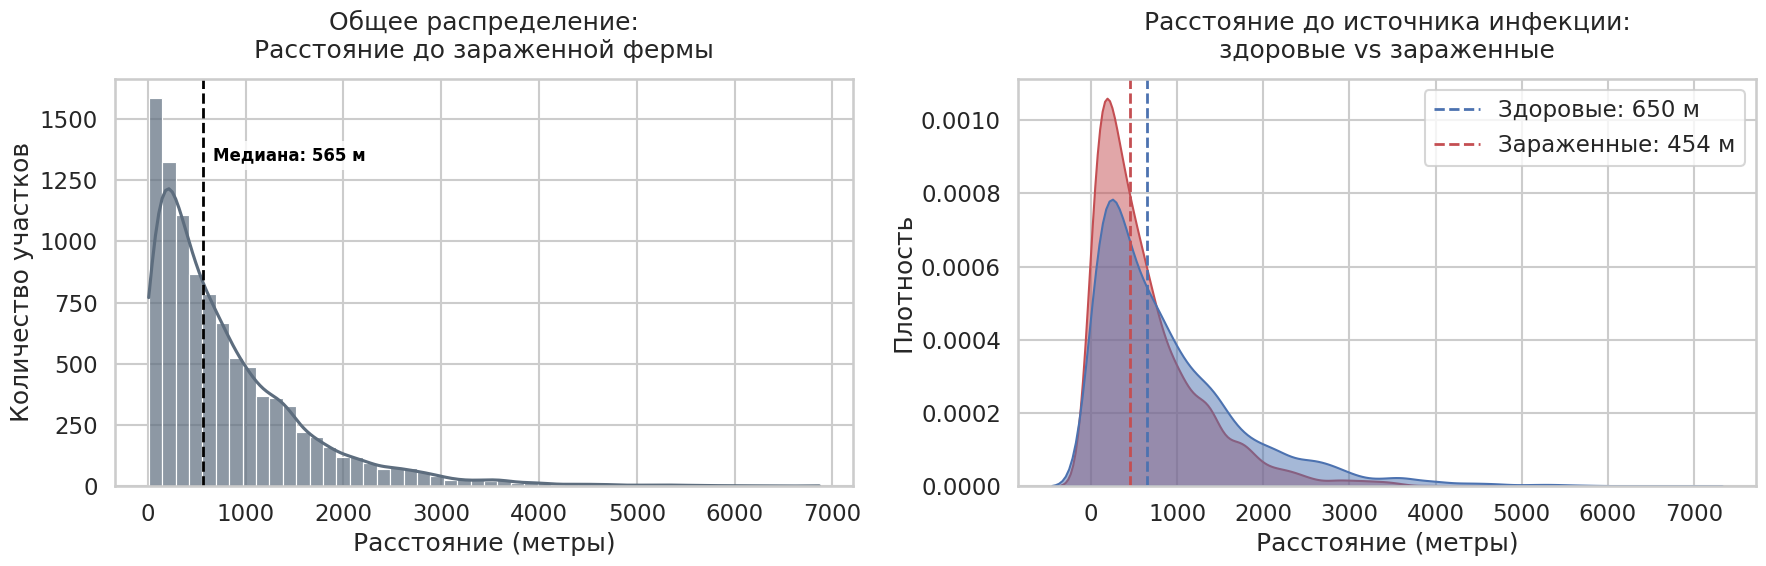

In [77]:
sns.set_theme(style="whitegrid", context="talk")

# Увеличиваем ширину холста, чтобы заголовки не наезжали друг на друга
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Общее распределение
sns.histplot(df["Distance_to_nearest_infected_farm_m"], bins=50, kde=True,
             color="#5D6D7E", alpha=0.7, ax=axes[0])
median_dist = df["Distance_to_nearest_infected_farm_m"].median()

# Рисуем линию медианы
axes[0].axvline(median_dist, color="black", linestyle="--", linewidth=2)

# ДОБАВЛЯЕМ ТЕКСТ прямо на график рядом с линией
axes[0].text(median_dist + 100, axes[0].get_ylim()[1] * 0.8,
             f"Медиана: {median_dist:.0f} м",
             color="black", fontweight="bold", fontsize=12,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

axes[0].set_title("Общее распределение:\nРасстояние до зараженной фермы", pad=15)
axes[0].set_xlabel("Расстояние (метры)")
axes[0].set_ylabel("Количество участков")


# 2. KDE по группам (Здоровые vs Зараженные)
sns.kdeplot(data=df, x="Distance_to_nearest_infected_farm_m", hue="Incidence",
            fill=True, common_norm=False, palette={0: "#4C72B0", 1: "#C44E52"},
            alpha=0.5, ax=axes[1])

median_d0 = df[df["Incidence"] == 0]["Distance_to_nearest_infected_farm_m"].median()
median_d1 = df[df["Incidence"] == 1]["Distance_to_nearest_infected_farm_m"].median()

# Рисуем линии медиан
axes[1].axvline(median_d0, color="#4C72B0", linestyle="--", linewidth=2, label=f"Здоровые: {median_d0:.0f} м")
axes[1].axvline(median_d1, color="#C44E52", linestyle="--", linewidth=2, label=f"Зараженные: {median_d1:.0f} м")

axes[1].set_title("Расстояние до источника инфекции:\nздоровые vs зараженные", pad=15)
axes[1].set_xlabel("Расстояние (метры)")
axes[1].set_ylabel("Плотность")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("fig_distance_distribution.png", dpi=150)
plt.show()

In [78]:
# Вывод статистики
print(df.groupby("Incidence")["Distance_to_nearest_infected_farm_m"].agg(
    ["mean", "median", "std", "min", "max"]).round(0))

            mean  median    std  min   max
Incidence                                 
0          906.0   650.0  890.0   10  6866
1          643.0   454.0  623.0   10  4948


Графики показывают различия в распределениях здоровых и пораженных участков. Медианное расстояние до ближайшей зараженной фермы у здоровых участков равно 650 м, тогда как у зараженных - 454 м. В среднем зараженные участки находятся на 200 метров ближе к источнику инфекции, чем здоровые.

Это говорит о том, что расстояние до пораженного участка является значимым фактором риска.

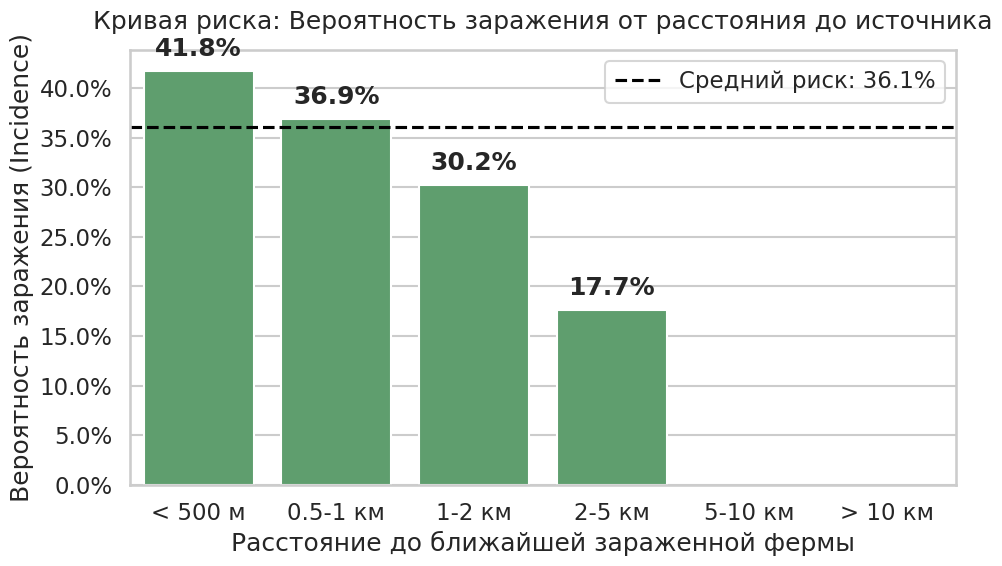

In [79]:
# 2. Кривая риска (Distance Decay)
# Задаем логичные интервалы (в метрах):
# 0-500, 500-1000 (1 км), 1000-2000 (2 км), 2000-5000 (5 км), 5000+
bins_d = [0, 500, 1000, 2000, 5000, 10000, np.inf]
labels_d = ["< 500 м", "0.5-1 км", "1-2 км", "2-5 км", "5-10 км", "> 10 км"]

df["dist_bin"] = pd.cut(df["Distance_to_nearest_infected_farm_m"],
                        bins=bins_d, labels=labels_d, include_lowest=True)

# Считаем риск в каждом бине
risk_curve_d = df.groupby("dist_bin", observed=True)["Incidence"].agg(["mean", "count"]).reset_index()
risk_curve_d = risk_curve_d[risk_curve_d["count"] >= 30] # Отсекаем шум, если есть

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=risk_curve_d, x="dist_bin", y="mean", color="#55A868", ax=ax)

ax.axhline(df["Incidence"].mean(), color="black", linestyle="--",
           label=f"Средний риск: {df['Incidence'].mean():.1%}")

ax.set_title("Кривая риска: Вероятность заражения от расстояния до источника", pad=15)
ax.set_xlabel("Расстояние до ближайшей зараженной фермы")
ax.set_ylabel("Вероятность заражения (Incidence)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend()

# Подписываем значения на столбцах
for i, p in enumerate(ax.patches):
    ax.text(p.get_x() + p.get_width()/2, p.get_height() + 0.01,
            f'{p.get_height():.1%}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("fig_risk_curve_distance.png", dpi=150)
plt.show()

Выборка ограничена участками, находящимися в радиусе до 5 км от известных очагов инфекции, что не позволяет оценить фоновый риск в изолированных регионах. Самый высокий риск у участков, у которых расстояние до ближайшего пораженного участка менее 500 м (41.8%). При расстоянии 1-2 км риск падает до 30.2% и до 17.7% при 2-5 км.

Так, в первую очередь нужно уделять внимание участкам, которые имеют в пределах 500м пораженные участки.

### NDVI

Индекс вегетации показывает густоту и здоровье растений. Высокий NDVI может говорить о здоровом растении с хорошим иммунитетом, но также густая крона является благоприятным фактором для развития кофейной ржавчины. Низкий NDVI может стать сигналом о развитии болезни, кофейная ржавчина вызывает опадение листьев.

Опадание листьев начинается через 4-7 недель после заражения патогеном.

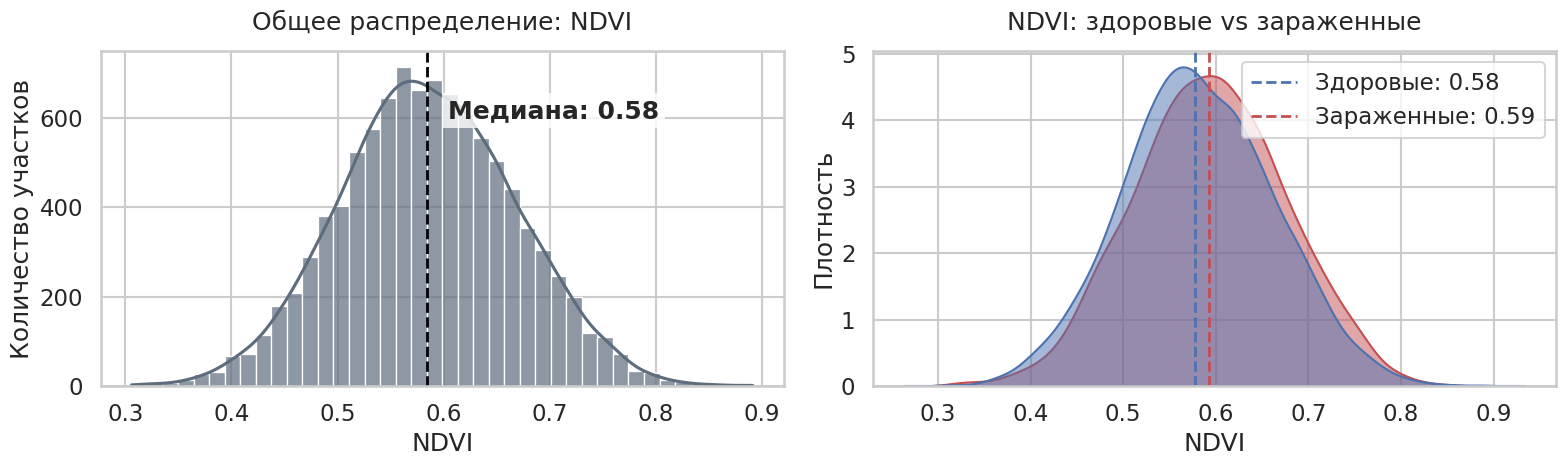

In [80]:
sns.set_theme(style="whitegrid", context="talk")

# 1. Распределение NDVI и сравнение групп
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Общее распределение
sns.histplot(df["NDVI"], bins=40, kde=True, color="#5D6D7E", alpha=0.7, ax=axes[0])
median_ndvi = df["NDVI"].median()
axes[0].axvline(median_ndvi, color="black", linestyle="--", linewidth=2)
axes[0].text(median_ndvi + 0.02, axes[0].get_ylim()[1] * 0.8,
             f"Медиана: {median_ndvi:.2f}", fontweight="bold",
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
axes[0].set_title("Общее распределение: NDVI", pad=15)
axes[0].set_xlabel("NDVI")
axes[0].set_ylabel("Количество участков")

# KDE по группам
sns.kdeplot(data=df, x="NDVI", hue="Incidence",
            fill=True, common_norm=False, palette={0: "#4C72B0", 1: "#C44E52"},
            alpha=0.5, ax=axes[1])
median_n0 = df[df["Incidence"] == 0]["NDVI"].median()
median_n1 = df[df["Incidence"] == 1]["NDVI"].median()
axes[1].axvline(median_n0, color="#4C72B0", linestyle="--", linewidth=2, label=f"Здоровые: {median_n0:.2f}")
axes[1].axvline(median_n1, color="#C44E52", linestyle="--", linewidth=2, label=f"Зараженные: {median_n1:.2f}")
axes[1].set_title("NDVI: здоровые vs зараженные", pad=15)
axes[1].set_xlabel("NDVI")
axes[1].set_ylabel("Плотность")
axes[1].legend()

plt.tight_layout()
plt.savefig("fig_ndvi_distribution.png", dpi=150)
plt.show()


In [81]:
print("Статистика по NDVI")
print(df.groupby("Incidence")["NDVI"].agg(["mean", "median", "std", "min", "max"]).round(3))

Статистика по NDVI
            mean  median    std    min    max
Incidence                                    
0          0.581   0.578  0.082  0.306  0.891
1          0.593   0.593  0.082  0.312  0.857


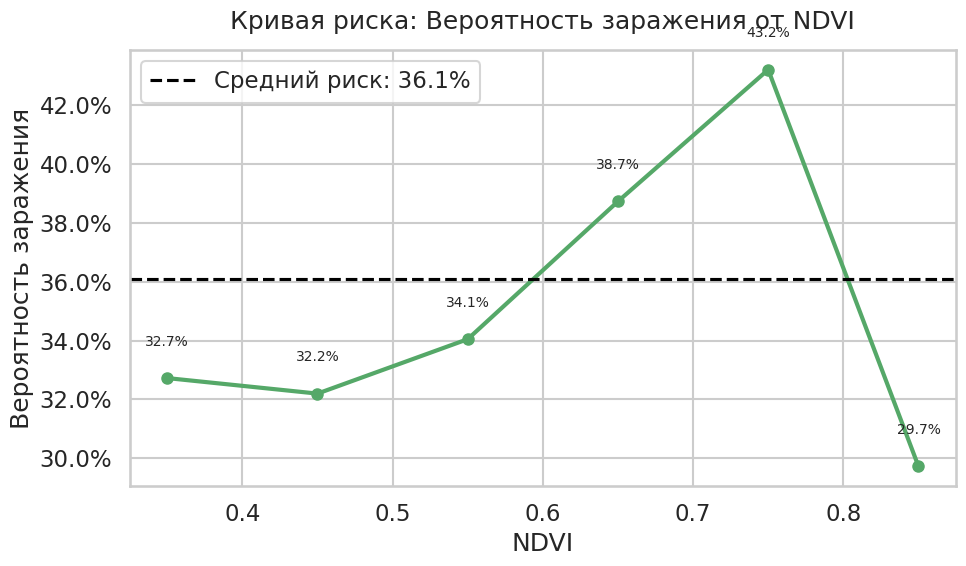

In [82]:
min_n = df["NDVI"].min()
max_n = df["NDVI"].max()
bins_n = np.arange(np.floor(min_n*10)/10, np.ceil(max_n*10)/10 + 0.1, 0.1)

df["ndvi_bin"] = pd.cut(df["NDVI"], bins=bins_n)
risk_curve_n = df.groupby("ndvi_bin", observed=True)["Incidence"].agg(["mean", "count"]).reset_index()
risk_curve_n = risk_curve_n[risk_curve_n["count"] >= 30]
risk_curve_n["mid"] = risk_curve_n["ndvi_bin"].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(risk_curve_n['mid'], risk_curve_n['mean'], marker='o', markersize=8, linewidth=3, color='#55A868')
ax.axhline(df["Incidence"].mean(), color="black", linestyle="--", label=f"Средний риск: {df['Incidence'].mean():.1%}")

ax.set_title("Кривая риска: Вероятность заражения от NDVI", pad=15)
ax.set_xlabel("NDVI")
ax.set_ylabel("Вероятность заражения")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend()

# Подписи точек
for x, y in zip(risk_curve_n['mid'], risk_curve_n['mean']):
    ax.text(x, y + 0.01, f'{y:.1%}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig("fig_risk_curve_ndvi.png", dpi=150)
plt.show()

Распределение здоровых и больных участков по данному признаку практически не отличается. Однако, у этого признака нелинейная связь. Но кривая риска показывает рост риска при показателях 0.65-0.75, 38.7%-43.2%. При значении выше 0.8 риск резко падает. Это может говорить о том, что такие участки обладают например густой кроной, но недостаточно сильны для борьбы с патогеном. Возможно, это стареющие растения. NDVI 0.8 может указывать на полновозрастные растения с более сильным иммунитетом.

**Пороговым значением является 0.65-0.75 NDVI (риск около 40%).**

/tmp/ipykernel_6744/2268326681.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_age_ndvi = df.pivot_table(


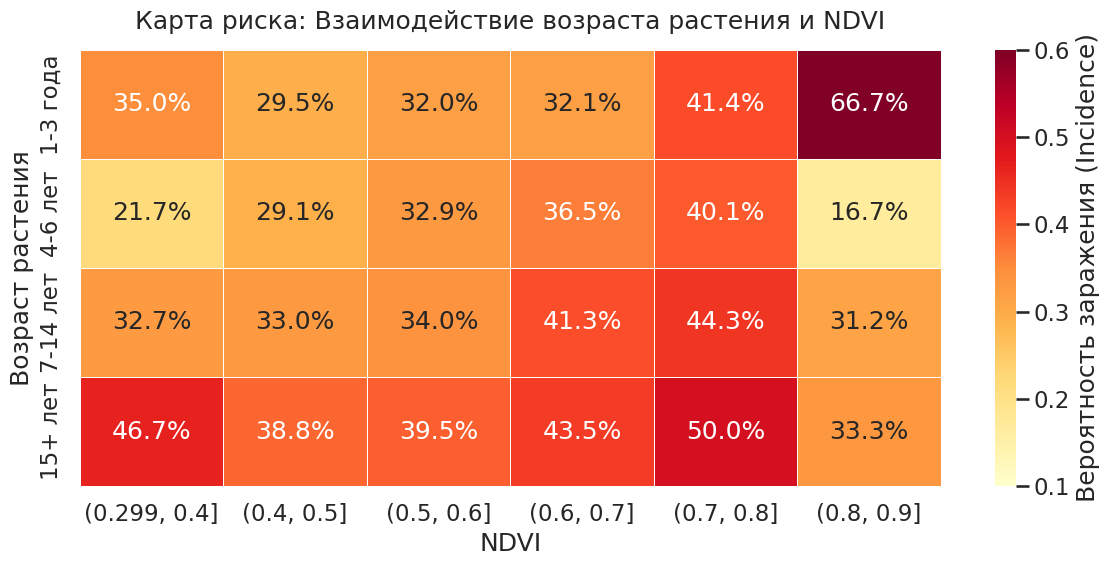

In [83]:
sns.set_theme(style="whitegrid", context="talk")

# 1. Создаем возрастные группы (на случай, если переменная не сохранена)
if 'Age_Group' not in df.columns:
    df['Age_Group'] = pd.cut(
        df['Plant_age_years'],
        bins=[0, 3, 6, 14, 100],
        labels=['1-3 года', '4-6 лет', '7-14 лет', '15+ лет'],
        include_lowest=True
    )

# 2. Разбиваем NDVI на интервалы (бины)
# Ограничим NDVI разумными пределами (например, от 0.3 до 0.9)
bins_ndvi = np.arange(0.3, 1.0, 0.1)
df['NDVI_bin'] = pd.cut(df['NDVI'], bins=bins_ndvi, include_lowest=True)

# 3. Строим сводную таблицу (Pivot)
pivot_age_ndvi = df.pivot_table(
    index='Age_Group',
    columns='NDVI_bin',
    values='Incidence',
    aggfunc='mean'
)

# 4. Рисуем тепловую карту
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(pivot_age_ndvi, annot=True, fmt=".1%", cmap="YlOrRd",
            linewidths=.5, cbar_kws={'label': 'Вероятность заражения (Incidence)'},
            ax=ax, vmin=0.1, vmax=0.6)

ax.set_title("Карта риска: Взаимодействие возраста растения и NDVI", pad=15)
ax.set_xlabel("NDVI")
ax.set_ylabel("Возраст растения")

# Переворачиваем ось Y, чтобы молодые были внизу (или оставляем как есть для удобства чтения)
# ax.invert_yaxis()

plt.tight_layout()
plt.savefig("fig_heatmap_age_ndvi.png", dpi=150)
plt.show()

Тепловая карта выявила нелинейную зависимость: риск растет с увеличением NDVI до 0.7–0.8 (густая крона создает благоприятные условия для патогена), но при NDVI > 0.8 у взрослых растений риск резко падает. Это указывает на то, что NDVI > 0.8 у зрелых деревьев показывает их устойчивость. Высокий показатель риска (66.7%) у ювенильных растений с NDVI > 0.8 может быть вызван как малым размером выборки, так и физиологическим дисбалансом (избыточный вегетативный рост в ущерб иммунитету, например, это может быть вызвано избытком азота для роста вегетирующей массы, но это также являтеся благоприятным фактором для развития грибных заболеваний).

### Корреляция признаков

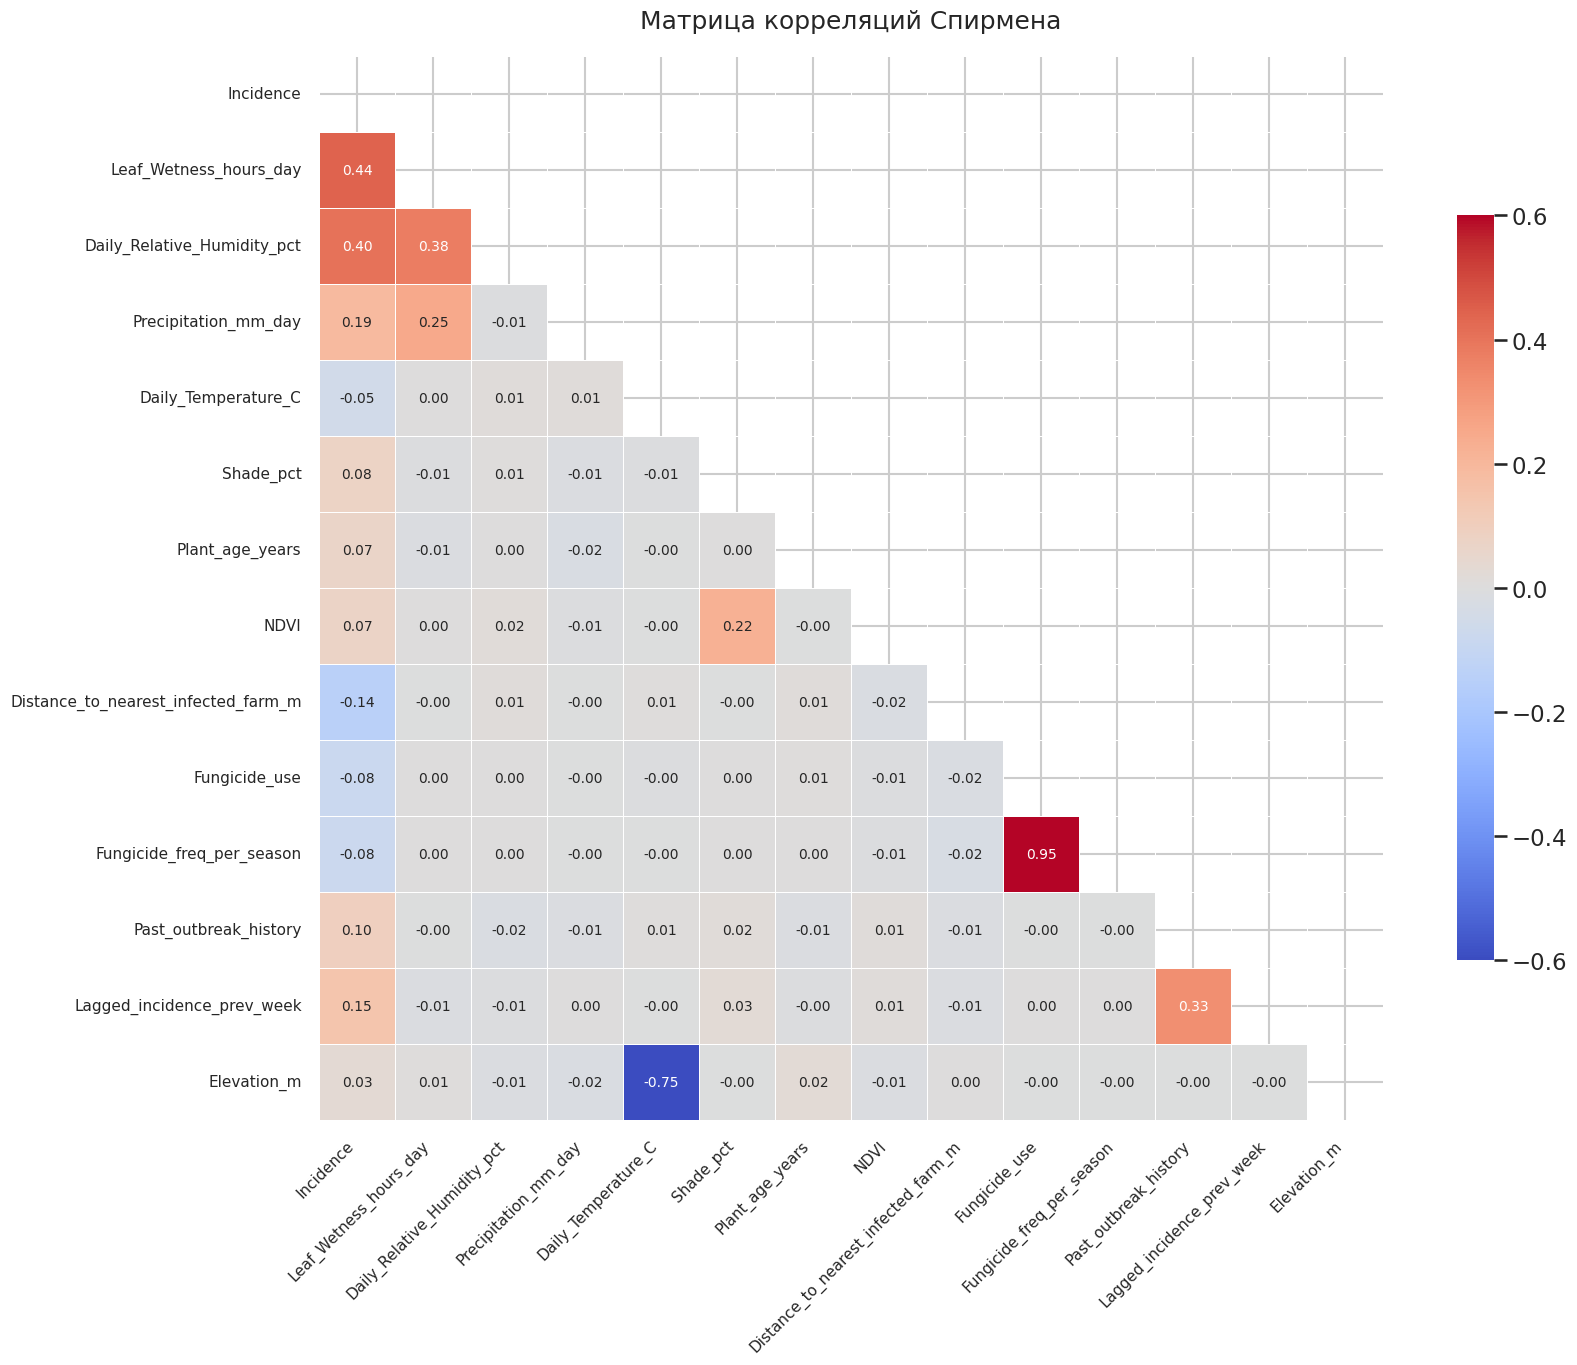

In [88]:
fig, ax = plt.subplots(figsize=(18, 14))
features_to_corr = [
    "Incidence",
    "Leaf_Wetness_hours_day",
    "Daily_Relative_Humidity_pct",
    "Precipitation_mm_day",
    "Daily_Temperature_C",
    "Shade_pct",
    "Plant_age_years",
    "NDVI",
    "Distance_to_nearest_infected_farm_m",
    "Fungicide_use",
    "Fungicide_freq_per_season",
    "Past_outbreak_history",
    "Lagged_incidence_prev_week",
    "Elevation_m"
]

df_corr = df[features_to_corr].copy()

# 2. Считаем матрицу корреляций Спирмена
corr_matrix = df_corr.corr(method="spearman")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# annot_kws={"size": 10} делает шрифт цифр аккуратным внутри ячеек
sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", vmin=-0.6, vmax=0.6,
            annot=True, fmt=".2f", annot_kws={"size": 10},
            square=True, linewidths=.5,
            cbar_kws={"shrink": .7}, ax=ax)

# Поворачиваем подписи по оси X, чтобы они не слипались
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)

ax.set_title("Матрица корреляций Спирмена", pad=20, fontsize=18)
plt.tight_layout()
plt.savefig("fig_final_corr_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

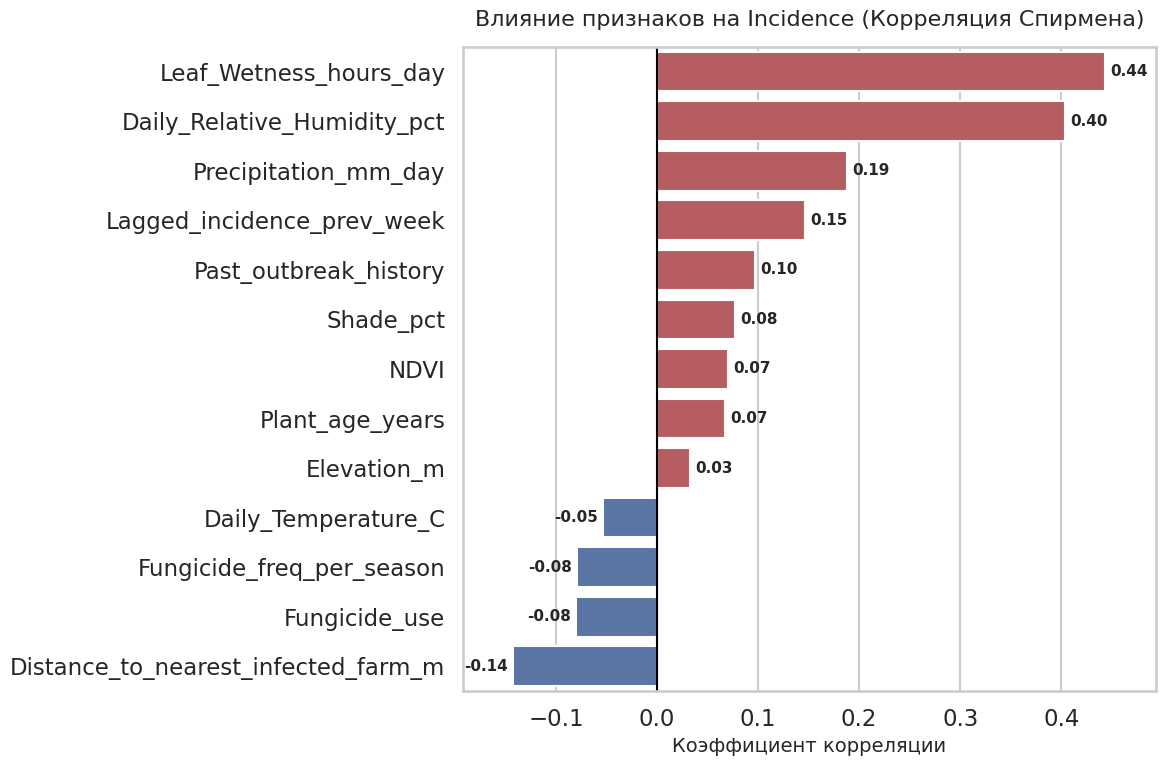

In [89]:
# 2. БАРЧАРТ (ВЛИЯНИЕ НА INCIDENCE)
target_corr = corr_matrix["Incidence"].drop("Incidence").sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))

# Убираем ошибку deprecation warning (добавляем hue и legend=False)
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in target_corr]
sns.barplot(x=target_corr.values, y=target_corr.index,
            hue=target_corr.index, palette=colors, legend=False, ax=ax)

ax.set_title("Влияние признаков на Incidence (Корреляция Спирмена)", pad=15, fontsize=16)
ax.set_xlabel("Коэффициент корреляции", fontsize=14)
ax.set_ylabel("")

# Делаем красивую вертикальную линию нуля
ax.axvline(0, color="black", linewidth=1.5)

# Находим минимальное и максимальное значение для настройки границ оси X
min_val = target_corr.values.min()
max_val = target_corr.values.max()

# Даем запас по краям оси, чтобы текст не обрезался
ax.set_xlim(min_val - 0.05, max_val + 0.05)

# Умная расстановка текста: если значение положительное - пишем справа,
# если отрицательное - слева (чтобы текст не наезжал на длинные названия)
for i, v in enumerate(target_corr.values):
    if v > 0:
        ax.text(v + 0.005, i, f"{v:.2f}", va='center', ha='left', fontweight='bold', fontsize=11)
    else:
        ax.text(v - 0.005, i, f"{v:.2f}", va='center', ha='right', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig("fig_final_corr_target.png", dpi=150, bbox_inches='tight')
plt.show()

* Наиболее значимые факторы: Корреляционный анализ Спирмена подтвердил, что длительность увлажнения листьев (ρ = 0.44) и относительная влажность воздуха (ρ = 0.40) являются главными факторами заражения кофейной ржавчиной. Наличие свободной влаги — необходимое условие для прорастания спор.

* Сдерживающие факторы: Расстояние до очага инфекции (ρ = -0.14) и применение фунгицидов (ρ = -0.08) отрицательно коррелируют с риском, подтверждая эффективность пространственной изоляции и химической защиты.

* Ограничения корреляции: Для таких признаков, как Temperature, NDVI и Shade_pct, линейная корреляция близка к нулю. Однако это не означает отсутствие связи: наш предшествующий EDA доказал, что их влияние на риск носит нелинейный характер.

* Мультиколлинеарность: Выявлена высокая связь между температурой и высотой над уровнем моря (ρ = -0.75), а также между фактом и частотой использования фунгицидов (ρ = 0.95). При построении прогностических моделей эти признаки потребуют отбора или регуляризации во избежание переобучения.